# Track B: SVM-Based PM₂.₅ AQI Alert Classification



The AQI target is independently constructed from observed PM₂.₅ concentrations
using the EPA PM₂.₅ NowCast procedure and established PM₂.₅ AQI breakpoints.

Two feature representations are evaluated:

1. Full-feature dataset
2. RFE/reduced-feature dataset

To address class imbalance, two SVM strategies are compared:

1. Class-weighted SVM-RBF
2. SMOTE + SVM-RBF

Temporal dependence is preserved using rolling-forward evaluation rather than
random K-fold shuffling.

The future regression target (`Target_PM2.5`) is excluded from the
classification predictors.

In [4]:
# ============================================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Reproducibility
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")
print(f"Random state: {RANDOM_STATE}")

Libraries imported successfully.
Random state: 42


## 2. Load the Prepared Model Datasets



In [5]:
# ============================================================
# 2. FILE PATHS
# ============================================================

FULL_DATA_PATH = "AirQuality_Full_Model_Dataset.csv"
RFE_DATA_PATH = "AirQuality_RFE_Model_Dataset.csv"

print("File paths defined.")
print("Full dataset:", FULL_DATA_PATH)
print("RFE dataset :", RFE_DATA_PATH)

File paths defined.
Full dataset: AirQuality_Full_Model_Dataset.csv
RFE dataset : AirQuality_RFE_Model_Dataset.csv


In [6]:
# ============================================================
# 3. LOAD DATASETS
# ============================================================

full_df = pd.read_csv(FULL_DATA_PATH)
rfe_df = pd.read_csv(RFE_DATA_PATH)

print("Datasets loaded successfully.\n")

print("Full-feature dataset shape:", full_df.shape)
print("RFE dataset shape         :", rfe_df.shape)

Datasets loaded successfully.

Full-feature dataset shape: (17519, 29)
RFE dataset shape         : (17519, 16)


In [7]:
# ============================================================
# 4. BASIC DATASET VERIFICATION
# ============================================================

print("FULL DATASET")
print("=" * 60)
print(full_df.info())

print("\nRFE DATASET")
print("=" * 60)
print(rfe_df.info())

FULL DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17519 entries, 0 to 17518
Data columns (total 29 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   PM10              17519 non-null  float64
 1   PM2.5             17519 non-null  float64
 2   RH                17519 non-null  float64
 3   Temp              17519 non-null  float64
 4   WD                17519 non-null  float64
 5   Hour              17519 non-null  int64  
 6   DayOfWeek         17519 non-null  int64  
 7   Weekend           17519 non-null  int64  
 8   Day               17519 non-null  int64  
 9   Harmattan         17519 non-null  int64  
 10  Hour_sin          17519 non-null  float64
 11  Hour_cos          17519 non-null  float64
 12  WD_sin            17519 non-null  float64
 13  WD_cos            17519 non-null  float64
 14  Month_sin         17519 non-null  float64
 15  Month_cos         17519 non-null  float64
 16  PM2.5_lag1        17519 non

In [8]:
# ============================================================
# 5. DISPLAY COLUMN STRUCTURE
# ============================================================

print("Full-feature columns:")
for i, col in enumerate(full_df.columns, start=1):
    print(f"{i:2d}. {col}")

print("\nRFE columns:")
for i, col in enumerate(rfe_df.columns, start=1):
    print(f"{i:2d}. {col}")

Full-feature columns:
 1. PM10
 2. PM2.5
 3. RH
 4. Temp
 5. WD
 6. Hour
 7. DayOfWeek
 8. Weekend
 9. Day
10. Harmattan
11. Hour_sin
12. Hour_cos
13. WD_sin
14. WD_cos
15. Month_sin
16. Month_cos
17. PM2.5_lag1
18. PM2.5_lag3
19. PM2.5_lag6
20. PM2.5_lag12
21. PM2.5_lag24
22. PM2.5_rollmean6
23. PM2.5_rollmean12
24. PM2.5_rollmean24
25. PM2.5_rollstd24
26. Temp_RH
27. PM2.5_RH
28. PM2.5_PM10_ratio
29. Target_PM2.5

RFE columns:
 1. PM10
 2. RH
 3. WD
 4. WD_cos
 5. PM2.5_lag1
 6. PM2.5_lag6
 7. PM2.5_lag12
 8. PM2.5_lag24
 9. PM2.5_rollmean6
10. PM2.5_rollmean12
11. PM2.5_rollmean24
12. PM2.5_rollstd24
13. Temp_RH
14. PM2.5_RH
15. PM2.5_PM10_ratio
16. Target_PM2.5


In [9]:
# ============================================================
# 6. VERIFY ROW ALIGNMENT
# ============================================================

print("Number of rows:")
print("Full:", len(full_df))
print("RFE :", len(rfe_df))

assert len(full_df) == len(rfe_df), (
    "Full and RFE datasets do not contain the same number of rows."
)

# The future regression target should be identical row-by-row.
target_alignment = np.allclose(
    full_df["Target_PM2.5"].values,
    rfe_df["Target_PM2.5"].values,
    equal_nan=True
)

print("\nTarget_PM2.5 row alignment:", target_alignment)

assert target_alignment, (
    "Target_PM2.5 is not aligned between Full and RFE datasets."
)

print("\nRow alignment verified successfully.")

Number of rows:
Full: 17519
RFE : 17519

Target_PM2.5 row alignment: True

Row alignment verified successfully.


In [10]:
# ============================================================
# 7. VERIFY OBSERVED PM2.5
# ============================================================

pm25 = full_df["PM2.5"]

print("Observed PM₂.₅ summary")
print("=" * 60)
print(pm25.describe())

print("\nMissing values:", pm25.isna().sum())
print("Minimum:", pm25.min())
print("Maximum:", pm25.max())

Observed PM₂.₅ summary
count    17519.000000
mean        24.657166
std         27.028627
min          1.540185
25%         12.323224
50%         17.257359
75%         26.844624
max        249.604800
Name: PM2.5, dtype: float64

Missing values: 0
Minimum: 1.5401845
Maximum: 249.6048


## 3. EPA PM₂.₅ NowCast Construction

The standard PM₂.₅ AQI is based on 24-hour PM₂.₅ concentrations. Because
this study requires an hourly public-facing air-quality alert classification,
the EPA NowCast approach is used to derive a current-condition PM₂.₅
concentration from recent hourly observations.

.

In [11]:
# ============================================================
# 8. EPA PM2.5 NOWCAST FUNCTION
# ============================================================

def calculate_nowcast(pm25_series, window=12, min_valid=2):
    """
    Calculate EPA-style PM2.5 NowCast values from hourly observations.

    Parameters
    ----------
    pm25_series : pandas.Series
        Chronologically ordered hourly PM2.5 observations.

    window : int
        Number of recent hourly observations used by the NowCast.
        EPA NowCast uses 12 hours.

    min_valid : int
        Minimum number of valid observations required.

    Returns
    -------
    pandas.Series
        NowCast PM2.5 concentrations.
    """

    values = pm25_series.astype(float).to_numpy()
    nowcast = np.full(len(values), np.nan)

    for t in range(len(values)):

        # Select current hour and preceding observations
        start = max(0, t - window + 1)
        recent = values[start:t + 1]

        # Remove missing observations
        valid = recent[~np.isnan(recent)]

        # Minimum-data requirement
        if len(valid) < min_valid:
            continue

        # Current value
        current = valid[-1]

        # Minimum and maximum concentration
        c_min = np.min(valid)
        c_max = np.max(valid)

        # If maximum concentration is zero,
        # there is no variability to calculate.
        if c_max == 0:
            weight = 1.0
        else:
            # Concentration variability rate
            rate = (c_max - c_min) / c_max

            # Dynamic weighting factor
            weight = 1 - rate

            # EPA minimum weighting factor
            weight = max(weight, 0.5)

        # Generate exponentially decreasing weights.
        # Most recent observation receives exponent 0.
        age = np.arange(len(valid) - 1, -1, -1)

        weights = weight ** age

        # Weighted NowCast concentration
        nowcast[t] = np.sum(valid * weights) / np.sum(weights)

    return pd.Series(nowcast, index=pm25_series.index)

In [12]:
# ============================================================
# 9. CALCULATE PM2.5 NOWCAST
# ============================================================

full_df["PM2.5_NowCast"] = calculate_nowcast(
    full_df["PM2.5"],
    window=12,
    min_valid=2
)

print("NowCast calculation completed.")
print()

print(full_df["PM2.5_NowCast"].describe())

NowCast calculation completed.

count    17518.000000
mean        24.668801
std         26.803499
min          2.087407
25%         12.575967
50%         17.323854
75%         26.841411
max        247.604754
Name: PM2.5_NowCast, dtype: float64


In [13]:
# ============================================================
# 10. INSPECT INITIAL NOWCAST VALUES
# ============================================================

initial_nowcast = full_df[
    ["PM2.5", "PM2.5_NowCast"]
].head(15)

display(initial_nowcast)

,PM2.5,PM2.5_NowCast
0,46.475690,NaN
1,49.260070,47.908370
2,65.935270,56.205500
3,74.101551,64.526461
4,68.002704,65.961734
5,57.365491,62.549249
6,55.529752,59.828435
7,64.628326,61.661783
8,65.230718,63.012606
9,59.365944,61.640165


In [14]:
# ============================================================
# 11. REQUIRE A COMPLETE 12-HOUR NOWCAST WINDOW
# ============================================================

full_df["NowCast_valid"] = False

# A complete 12-hour window becomes available at observation 12.
full_df.loc[full_df.index >= 11, "NowCast_valid"] = True

# Since the observed PM2.5 series contains no missing values,
# all observations from index 11 onward should have valid NowCast values.
full_df.loc[
    full_df["NowCast_valid"],
    "NowCast_valid"
] = full_df.loc[
    full_df["NowCast_valid"],
    "PM2.5_NowCast"
].notna()

print("Total observations:", len(full_df))
print("Valid NowCast observations:", full_df["NowCast_valid"].sum())
print("Invalid/initial observations:", (~full_df["NowCast_valid"]).sum())

Total observations: 17519
Valid NowCast observations: 17508
Invalid/initial observations: 11


In [15]:
# ============================================================
# 12. VERIFY NOWCAST RANGE
# ============================================================

valid_nowcast = full_df.loc[
    full_df["NowCast_valid"],
    "PM2.5_NowCast"
]

print("Valid NowCast observations:", len(valid_nowcast))
print("Minimum NowCast PM₂.₅:", valid_nowcast.min())
print("Maximum NowCast PM₂.₅:", valid_nowcast.max())
print("Mean NowCast PM₂.₅:", valid_nowcast.mean())

Valid NowCast observations: 17508
Minimum NowCast PM₂.₅: 2.0874065405698
Maximum NowCast PM₂.₅: 247.60475371494945
Mean NowCast PM₂.₅: 24.64845166011032


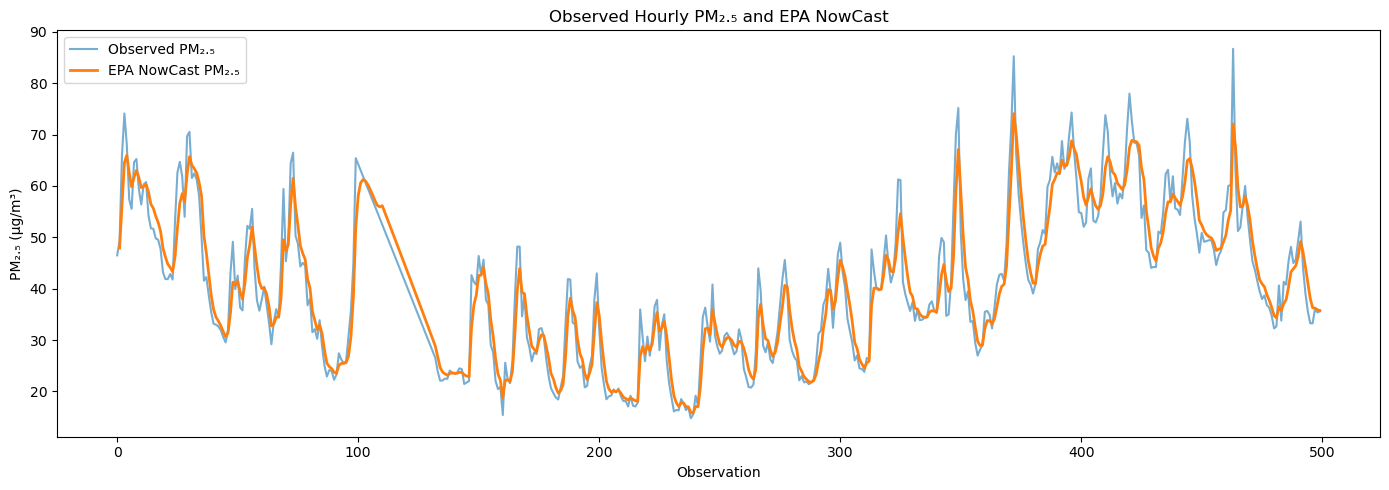

In [16]:
# ============================================================
# 13. VISUALIZE OBSERVED PM2.5 AND NOWCAST
# ============================================================

plot_df = full_df.iloc[:500].copy()

plt.figure(figsize=(14, 5))

plt.plot(
    plot_df.index,
    plot_df["PM2.5"],
    label="Observed PM₂.₅",
    alpha=0.6
)

plt.plot(
    plot_df.index,
    plot_df["PM2.5_NowCast"],
    label="EPA NowCast PM₂.₅",
    linewidth=2
)

plt.xlabel("Observation")
plt.ylabel("PM₂.₅ (µg/m³)")
plt.title("Observed Hourly PM₂.₅ and EPA NowCast")
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# 14. NOWCAST SANITY CHECKS
# ============================================================

valid = full_df["NowCast_valid"]

# No missing values among valid observations
assert full_df.loc[valid, "PM2.5_NowCast"].notna().all()

# NowCast should never be negative
assert (full_df.loc[valid, "PM2.5_NowCast"] >= 0).all()

# Exactly 11 initial observations should be excluded
assert (~valid).sum() == 11

# Expected number of valid observations
assert valid.sum() == len(full_df) - 11

print("✓ No missing NowCast values among valid observations")
print("✓ No negative NowCast concentrations")
print("✓ First 11 observations correctly excluded")
print("✓ 17,508 valid NowCast observations confirmed")

✓ No missing NowCast values among valid observations
✓ No negative NowCast concentrations
✓ First 11 observations correctly excluded
✓ 17,508 valid NowCast observations confirmed


## 4. PM₂.₅ NowCast to AQI Conversion

The valid NowCast PM₂.₅ concentrations are converted to AQI values using
the established PM₂.₅ AQI concentration breakpoints.


In [ ]:
# ============================================================
# 15. EPA PM2.5 AQI BREAKPOINTS
# ============================================================

aqi_breakpoints = pd.DataFrame({
    "AQI_Low": [0, 51, 101, 151, 201, 301],
    "AQI_High": [50, 100, 150, 200, 300, 500],
    "PM25_Low": [0.0, 9.1, 35.5, 55.5, 125.5, 225.5],
    "PM25_High": [9.0, 35.4, 55.4, 125.4, 225.4, 325.4],
    "Category": [
        "Good",
        "Moderate",
        "Unhealthy for Sensitive Groups",
        "Unhealthy",
        "Very Unhealthy",
        "Hazardous"
    ]
})

display(aqi_breakpoints)

In [19]:
# ============================================================
# 16. AQI CONVERSION FUNCTION
# ============================================================

def pm25_to_aqi(pm25):
    """
    Convert PM2.5 concentration to AQI using EPA PM2.5 breakpoints.

    PM2.5 concentration is truncated to one decimal place before
    interpolation.
    """

    if pd.isna(pm25):
        return np.nan

    # Truncate, rather than round, to one decimal place
    concentration = np.floor(pm25 * 10) / 10

    for _, row in aqi_breakpoints.iterrows():

        if (
            concentration >= row["PM25_Low"]
            and concentration <= row["PM25_High"]
        ):

            aqi = (
                (row["AQI_High"] - row["AQI_Low"])
                / (row["PM25_High"] - row["PM25_Low"])
            ) * (
                concentration - row["PM25_Low"]
            ) + row["AQI_Low"]

            return int(round(aqi))

    # Concentrations above the defined Hazardous range
    if concentration > aqi_breakpoints["PM25_High"].max():
        return 500

    return np.nan

In [20]:
# ============================================================
# 17. TEST AQI CONVERSION AT BREAKPOINTS
# ============================================================

test_concentrations = [
    0.0,
    9.0,
    9.1,
    35.4,
    35.5,
    55.4,
    55.5,
    125.4,
    125.5,
    225.4,
    225.5,
    325.4
]

test_results = pd.DataFrame({
    "PM2.5": test_concentrations,
    "AQI": [pm25_to_aqi(x) for x in test_concentrations]
})

display(test_results)

,PM2.5,AQI
0,0.0,0
1,9.0,50
2,9.1,51
3,35.4,100
4,35.5,101
5,55.4,150
6,55.5,151
7,125.4,200
8,125.5,201
9,225.4,300


In [21]:
# ============================================================
# 18. CONVERT NOWCAST PM2.5 TO AQI
# ============================================================

full_df["AQI"] = np.nan

valid_mask = full_df["NowCast_valid"]

full_df.loc[valid_mask, "AQI"] = (
    full_df.loc[valid_mask, "PM2.5_NowCast"]
    .apply(pm25_to_aqi)
)

print("AQI calculation completed.")
print()
print("Total observations:", len(full_df))
print("Valid AQI observations:", full_df["AQI"].notna().sum())
print("Missing AQI observations:", full_df["AQI"].isna().sum())

AQI calculation completed.

Total observations: 17519
Valid AQI observations: 17508
Missing AQI observations: 11


In [22]:
# ============================================================
# 19. AQI SUMMARY
# ============================================================

print("AQI summary statistics")
print("=" * 60)

print(
    full_df.loc[valid_mask, "AQI"].describe()
)

print("\nUnique AQI values:")
print(
    full_df.loc[valid_mask, "AQI"]
    .nunique()
)

print("\nAQI range:")
print(
    full_df.loc[valid_mask, "AQI"].min(),
    "to",
    full_df.loc[valid_mask, "AQI"].max()
)

AQI summary statistics
count    17508.000000
mean        77.289696
std         37.128465
min         11.000000
25%         57.000000
50%         66.000000
75%         84.000000
max        345.000000
Name: AQI, dtype: float64

Unique AQI values:
305

AQI range:
11.0 to 345.0


In [23]:
# ============================================================
# 20. VERIFY AQI VALUES
# ============================================================

valid_aqi = full_df.loc[valid_mask, "AQI"]

assert valid_aqi.notna().all(), (
    "Some valid NowCast observations produced missing AQI values."
)

assert (valid_aqi >= 0).all(), (
    "AQI contains negative values."
)

assert np.all(valid_aqi == np.floor(valid_aqi)), (
    "AQI contains non-integer values."
)

print("✓ All valid AQI values are non-negative integers.")
print("✓ No unexpected missing AQI values.")

✓ All valid AQI values are non-negative integers.
✓ No unexpected missing AQI values.


## 6. AQI Category Construction

The numerical AQI values are mapped to six categorical air-quality
conditions:

- Good: AQI 0–50
- Moderate: AQI 51–100
- Unhealthy for Sensitive Groups: AQI 101–150
- Unhealthy: AQI 151–200
- Very Unhealthy: AQI 201–300
- Hazardous: AQI 301–500

The resulting category is the classification target for the independent
SVM-RBF alert-classification track.

In [24]:
# ============================================================
# 21. AQI CATEGORY FUNCTION
# ============================================================

def aqi_to_category(aqi):
    """
    Map numerical AQI values to the six study AQI categories.
    """

    if pd.isna(aqi):
        return np.nan

    if 0 <= aqi <= 50:
        return "Good"

    elif 51 <= aqi <= 100:
        return "Moderate"

    elif 101 <= aqi <= 150:
        return "Unhealthy for Sensitive Groups"

    elif 151 <= aqi <= 200:
        return "Unhealthy"

    elif 201 <= aqi <= 300:
        return "Very Unhealthy"

    elif 301 <= aqi <= 500:
        return "Hazardous"

    else:
        return np.nan

In [25]:
# ============================================================
# 22. GENERATE AQI CATEGORIES
# ============================================================

full_df["AQI_Category"] = full_df["AQI"].apply(aqi_to_category)

print("AQI category generation completed.")
print()

print(
    full_df["AQI_Category"]
    .value_counts(dropna=False)
)

AQI category generation completed.

AQI_Category
Moderate                          13584
Unhealthy for Sensitive Groups     1560
Good                               1439
Unhealthy                           596
Very Unhealthy                      285
Hazardous                            44
NaN                                  11
Name: count, dtype: int64


In [26]:
# ============================================================
# 23. TEST AQI CATEGORY BOUNDARIES
# ============================================================

test_aqi_values = [
    0, 50,
    51, 100,
    101, 150,
    151, 200,
    201, 300,
    301, 500
]

category_test = pd.DataFrame({
    "AQI": test_aqi_values,
    "Category": [
        aqi_to_category(x)
        for x in test_aqi_values
    ]
})

display(category_test)

,AQI,Category
0,0,Good
1,50,Good
2,51,Moderate
3,100,Moderate
4,101,Unhealthy for Sensitive Groups
5,150,Unhealthy for Sensitive Groups
6,151,Unhealthy
7,200,Unhealthy
8,201,Very Unhealthy
9,300,Very Unhealthy


In [27]:
# ============================================================
# 24. FINAL AQI LABEL VALIDATION
# ============================================================

valid_labels = full_df.loc[valid_mask, "AQI_Category"]

print("Valid AQI observations:", len(valid_labels))
print("Missing categories:", valid_labels.isna().sum())
print("Number of categories:", valid_labels.nunique())

assert len(valid_labels) == 17508
assert valid_labels.isna().sum() == 0
assert valid_labels.nunique() == 6

print("\n✓ All 17,508 valid AQI observations have a category.")
print("✓ All six AQI categories are represented.")

Valid AQI observations: 17508
Missing categories: 0
Number of categories: 6

✓ All 17,508 valid AQI observations have a category.
✓ All six AQI categories are represented.


In [28]:
# ============================================================
# 25. AQI CLASS DISTRIBUTION
# ============================================================

aqi_distribution = (
    full_df.loc[valid_mask, "AQI_Category"]
    .value_counts()
    .reindex([
        "Good",
        "Moderate",
        "Unhealthy for Sensitive Groups",
        "Unhealthy",
        "Very Unhealthy",
        "Hazardous"
    ])
)

aqi_percentage = (
    aqi_distribution / aqi_distribution.sum() * 100
)

aqi_summary = pd.DataFrame({
    "Count": aqi_distribution,
    "Percentage": aqi_percentage.round(2)
})

display(aqi_summary)

,Count,Percentage
AQI_Category,,
Good,1439,8.22
Moderate,13584,77.59
Unhealthy for Sensitive Groups,1560,8.91
Unhealthy,596,3.40
Very Unhealthy,285,1.63
Hazardous,44,0.25


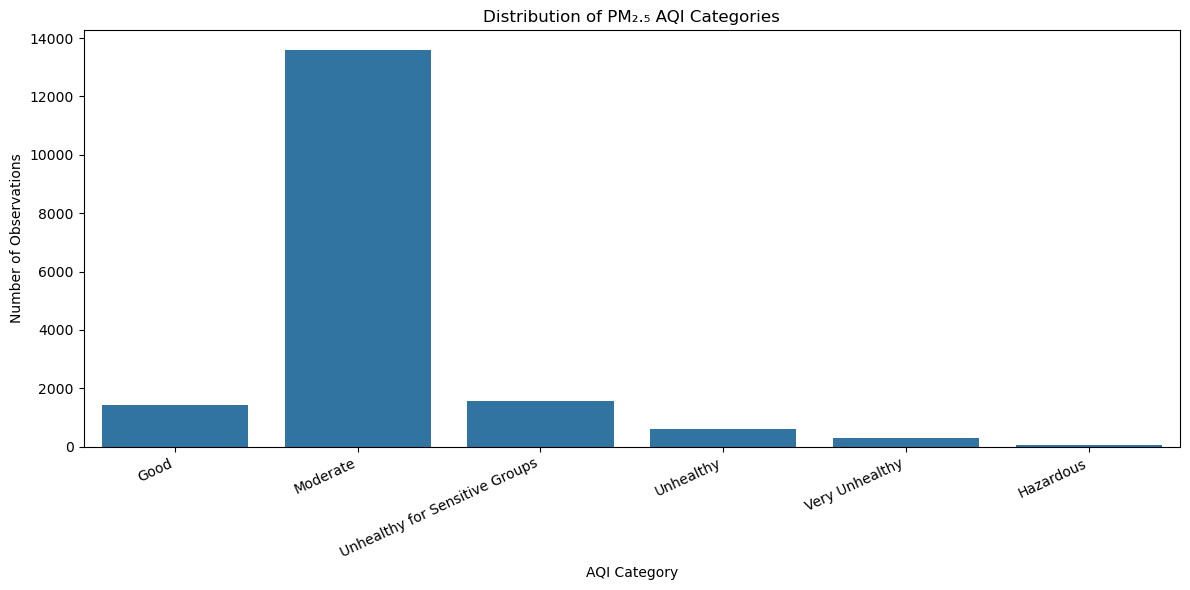

In [29]:
# ============================================================
# 26. VISUALIZE AQI CLASS DISTRIBUTION
# ============================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    x=aqi_summary.index,
    y=aqi_summary["Count"]
)

plt.xlabel("AQI Category")
plt.ylabel("Number of Observations")
plt.title("Distribution of PM₂.₅ AQI Categories")

plt.xticks(
    rotation=25,
    ha="right"
)

plt.tight_layout()
plt.show()

## 7. Prepare Full and RFE Classification Datasets



In [30]:
# ============================================================
# 27. CREATE COMMON VALID CLASSIFICATION MASK
# ============================================================

classification_mask = (
    full_df["NowCast_valid"]
    & full_df["AQI_Category"].notna()
)

print("Total observations:", len(full_df))
print("Valid classification observations:", classification_mask.sum())
print("Excluded observations:", (~classification_mask).sum())

assert classification_mask.sum() == 17508
assert (~classification_mask).sum() == 11

print("\n✓ Common classification sample established.")

Total observations: 17519
Valid classification observations: 17508
Excluded observations: 11

✓ Common classification sample established.


In [31]:
# ============================================================
# 28. ATTACH COMMON AQI TARGET TO RFE DATASET
# ============================================================

rfe_df["AQI"] = full_df["AQI"]
rfe_df["AQI_Category"] = full_df["AQI_Category"]

print("AQI target attached to RFE dataset.")

AQI target attached to RFE dataset.


In [32]:
# ============================================================
# 29. VERIFY AQI TARGET ALIGNMENT
# ============================================================

aqi_alignment = (
    full_df["AQI_Category"].astype("string").equals(
        rfe_df["AQI_Category"].astype("string")
    )
)

print("AQI category alignment:", aqi_alignment)

assert aqi_alignment, (
    "AQI categories are not aligned between Full and RFE datasets."
)

print("✓ AQI labels are identically aligned.")

AQI category alignment: True
✓ AQI labels are identically aligned.


In [33]:
# ============================================================
# 30. DEFINE CLASSIFICATION PREDICTORS
# ============================================================

EXCLUDED_COLUMNS = [
    "Target_PM2.5",
    "AQI",
    "AQI_Category",
    "PM2.5_NowCast",
    "NowCast_valid"
]

full_feature_columns = [
    col for col in full_df.columns
    if col not in EXCLUDED_COLUMNS
]

rfe_feature_columns = [
    col for col in rfe_df.columns
    if col not in EXCLUDED_COLUMNS
]

print("Number of Full predictors:", len(full_feature_columns))
print("Number of RFE predictors :", len(rfe_feature_columns))

print("\nFull predictors:")
print(full_feature_columns)

print("\nRFE predictors:")
print(rfe_feature_columns)

Number of Full predictors: 28
Number of RFE predictors : 15

Full predictors:
['PM10', 'PM2.5', 'RH', 'Temp', 'WD', 'Hour', 'DayOfWeek', 'Weekend', 'Day', 'Harmattan', 'Hour_sin', 'Hour_cos', 'WD_sin', 'WD_cos', 'Month_sin', 'Month_cos', 'PM2.5_lag1', 'PM2.5_lag3', 'PM2.5_lag6', 'PM2.5_lag12', 'PM2.5_lag24', 'PM2.5_rollmean6', 'PM2.5_rollmean12', 'PM2.5_rollmean24', 'PM2.5_rollstd24', 'Temp_RH', 'PM2.5_RH', 'PM2.5_PM10_ratio']

RFE predictors:
['PM10', 'RH', 'WD', 'WD_cos', 'PM2.5_lag1', 'PM2.5_lag6', 'PM2.5_lag12', 'PM2.5_lag24', 'PM2.5_rollmean6', 'PM2.5_rollmean12', 'PM2.5_rollmean24', 'PM2.5_rollstd24', 'Temp_RH', 'PM2.5_RH', 'PM2.5_PM10_ratio']


In [34]:
# ============================================================
# 31. CREATE CLASSIFICATION MATRICES
# ============================================================

X_full = full_df.loc[
    classification_mask,
    full_feature_columns
].copy()

X_rfe = rfe_df.loc[
    classification_mask,
    rfe_feature_columns
].copy()

y = full_df.loc[
    classification_mask,
    "AQI_Category"
].copy()

print("Full X shape:", X_full.shape)
print("RFE X shape :", X_rfe.shape)
print("y shape     :", y.shape)

Full X shape: (17508, 28)
RFE X shape : (17508, 15)
y shape     : (17508,)


In [35]:
# ============================================================
# 32. CHECK CLASSIFICATION PREDICTORS
# ============================================================

print("Missing values in Full predictors:", X_full.isna().sum().sum())
print("Missing values in RFE predictors :", X_rfe.isna().sum().sum())

print("\nNon-numeric Full predictors:")
print(
    X_full.select_dtypes(exclude=np.number).columns.tolist()
)

print("\nNon-numeric RFE predictors:")
print(
    X_rfe.select_dtypes(exclude=np.number).columns.tolist()
)

Missing values in Full predictors: 0
Missing values in RFE predictors : 0

Non-numeric Full predictors:
[]

Non-numeric RFE predictors:
[]


In [36]:
# ============================================================
# 33. VERIFY FUTURE TARGET EXCLUSION
# ============================================================

assert "Target_PM2.5" not in X_full.columns
assert "Target_PM2.5" not in X_rfe.columns

assert "AQI_Category" not in X_full.columns
assert "AQI_Category" not in X_rfe.columns

assert "PM2.5_NowCast" not in X_full.columns
assert "PM2.5_NowCast" not in X_rfe.columns

print("✓ Target_PM2.5 excluded from classification predictors.")
print("✓ AQI target excluded from predictors.")
print("✓ Derived NowCast AQI-label variable excluded from predictors.")

✓ Target_PM2.5 excluded from classification predictors.
✓ AQI target excluded from predictors.
✓ Derived NowCast AQI-label variable excluded from predictors.


In [37]:
# ============================================================
# 34. FINAL FEATURE REPRESENTATION CHECK
# ============================================================

print("=" * 70)
print("CLASSIFICATION DATASET SUMMARY")
print("=" * 70)

print(f"Observations       : {len(y):,}")
print(f"Full predictors    : {X_full.shape[1]}")
print(f"RFE predictors     : {X_rfe.shape[1]}")
print(f"Target classes     : {y.nunique()}")
print(f"Target observations: {y.notna().sum():,}")

print("\nClass distribution:")
print(y.value_counts())

CLASSIFICATION DATASET SUMMARY
Observations       : 17,508
Full predictors    : 28
RFE predictors     : 15
Target classes     : 6
Target observations: 17,508

Class distribution:
AQI_Category
Moderate                          13584
Unhealthy for Sensitive Groups     1560
Good                               1439
Unhealthy                           596
Very Unhealthy                      285
Hazardous                            44
Name: count, dtype: int64


## 8. Rolling-Forward Temporal Evaluation


In [38]:
# ============================================================
# 35. INSPECT TEMPORAL AQI DISTRIBUTION
# ============================================================

temporal_check = pd.DataFrame({
    "AQI_Category": y.values
})

temporal_check["Observation"] = np.arange(len(temporal_check))

# Divide the observations into five chronological blocks
temporal_check["Time_Block"] = pd.qcut(
    temporal_check["Observation"],
    q=5,
    labels=[
        "Block 1",
        "Block 2",
        "Block 3",
        "Block 4",
        "Block 5"
    ]
)

temporal_distribution = pd.crosstab(
    temporal_check["Time_Block"],
    temporal_check["AQI_Category"],
    normalize="index"
) * 100

temporal_distribution = temporal_distribution.reindex(
    columns=[
        "Good",
        "Moderate",
        "Unhealthy for Sensitive Groups",
        "Unhealthy",
        "Very Unhealthy",
        "Hazardous"
    ],
    fill_value=0
)

display(temporal_distribution.round(2))

AQI_Category,Good,Moderate,Unhealthy for Sensitive Groups,Unhealthy,Very Unhealthy,Hazardous
Time_Block,,,,,,
Block 1,3.71,67.93,14.39,6.71,6.20,1.06
Block 2,19.62,80.26,0.11,0.00,0.00,0.00
Block 3,1.28,58.11,28.24,10.22,1.94,0.20
Block 4,7.65,91.46,0.89,0.00,0.00,0.00
Block 5,8.82,90.18,0.91,0.09,0.00,0.00


In [39]:
# ============================================================
# 36. DEFINE ROLLING-FORWARD FOLDS
# ============================================================

n_samples = len(y)

initial_train_size = int(n_samples * 0.60)
test_size = int(n_samples * 0.10)

rolling_splits = []

for fold in range(4):

    train_end = initial_train_size + (fold * test_size)
    test_start = train_end
    test_end = test_start + test_size

    if test_end > n_samples:
        break

    train_indices = np.arange(0, train_end)
    test_indices = np.arange(test_start, test_end)

    rolling_splits.append(
        (train_indices, test_indices)
    )

print("Number of rolling folds:", len(rolling_splits))

for i, (train_idx, test_idx) in enumerate(
    rolling_splits, start=1
):
    print(
        f"Fold {i}: "
        f"Train = {len(train_idx):,} observations | "
        f"Test = {len(test_idx):,} observations | "
        f"Train end = {train_idx[-1]} | "
        f"Test range = {test_idx[0]}–{test_idx[-1]}"
    )

Number of rolling folds: 4
Fold 1: Train = 10,504 observations | Test = 1,750 observations | Train end = 10503 | Test range = 10504–12253
Fold 2: Train = 12,254 observations | Test = 1,750 observations | Train end = 12253 | Test range = 12254–14003
Fold 3: Train = 14,004 observations | Test = 1,750 observations | Train end = 14003 | Test range = 14004–15753
Fold 4: Train = 15,754 observations | Test = 1,750 observations | Train end = 15753 | Test range = 15754–17503


In [40]:
# ============================================================
# 37. VERIFY TEMPORAL INTEGRITY OF ROLLING FOLDS
# ============================================================

for fold_number, (train_idx, test_idx) in enumerate(
    rolling_splits, start=1
):

    # Training must occur entirely before testing
    assert train_idx.max() < test_idx.min()

    # Training indices must be chronological
    assert np.all(np.diff(train_idx) == 1)

    # Test indices must be chronological
    assert np.all(np.diff(test_idx) == 1)

    # No overlap
    assert len(
        np.intersect1d(train_idx, test_idx)
    ) == 0

    print(f"✓ Fold {fold_number}: temporal integrity verified.")

print("\nAll rolling-forward folds are valid.")

✓ Fold 1: temporal integrity verified.
✓ Fold 2: temporal integrity verified.
✓ Fold 3: temporal integrity verified.
✓ Fold 4: temporal integrity verified.

All rolling-forward folds are valid.


In [41]:
# ============================================================
# 38. CHECK CLASS COVERAGE IN EACH TEST WINDOW
# ============================================================

for fold_number, (_, test_idx) in enumerate(
    rolling_splits, start=1
):

    fold_y = y.iloc[test_idx]

    print("\n" + "=" * 70)
    print(f"FOLD {fold_number} TEST CLASS DISTRIBUTION")
    print("=" * 70)

    counts = (
        fold_y
        .value_counts()
        .reindex([
            "Good",
            "Moderate",
            "Unhealthy for Sensitive Groups",
            "Unhealthy",
            "Very Unhealthy",
            "Hazardous"
        ], fill_value=0)
    )

    percentages = (
        counts / len(fold_y) * 100
    ).round(2)

    display(
        pd.DataFrame({
            "Count": counts,
            "Percentage": percentages
        })
    )


FOLD 1 TEST CLASS DISTRIBUTION


,Count,Percentage
AQI_Category,,
Good,171,9.77
Moderate,1560,89.14
Unhealthy for Sensitive Groups,19,1.09
Unhealthy,0,0.00
Very Unhealthy,0,0.00
Hazardous,0,0.00



FOLD 2 TEST CLASS DISTRIBUTION


,Count,Percentage
AQI_Category,,
Good,97,5.54
Moderate,1641,93.77
Unhealthy for Sensitive Groups,12,0.69
Unhealthy,0,0.00
Very Unhealthy,0,0.00
Hazardous,0,0.00



FOLD 3 TEST CLASS DISTRIBUTION


,Count,Percentage
AQI_Category,,
Good,266,15.2
Moderate,1484,84.8
Unhealthy for Sensitive Groups,0,0.0
Unhealthy,0,0.0
Very Unhealthy,0,0.0
Hazardous,0,0.0



FOLD 4 TEST CLASS DISTRIBUTION


,Count,Percentage
AQI_Category,,
Good,43,2.46
Moderate,1676,95.77
Unhealthy for Sensitive Groups,31,1.77
Unhealthy,0,0.00
Very Unhealthy,0,0.00
Hazardous,0,0.00


In [42]:
# ============================================================
# 38. CHECK CLASS COVERAGE IN EACH TEST WINDOW
# ============================================================

class_order = [
    "Good",
    "Moderate",
    "Unhealthy for Sensitive Groups",
    "Unhealthy",
    "Very Unhealthy",
    "Hazardous"
]

for fold_number, (_, test_idx) in enumerate(
    rolling_splits, start=1
):

    fold_y = y.iloc[test_idx]

    counts = (
        fold_y
        .value_counts()
        .reindex(class_order, fill_value=0)
    )

    percentages = (
        counts / len(fold_y) * 100
    ).round(2)

    fold_summary = pd.DataFrame({
        "AQI Category": class_order,
        "Count": counts.values,
        "Percentage": percentages.values
    })

    print("\n" + "=" * 70)
    print(f"FOLD {fold_number} TEST CLASS DISTRIBUTION")
    print("=" * 70)
    print(fold_summary.to_string(index=False))


FOLD 1 TEST CLASS DISTRIBUTION
                  AQI Category  Count  Percentage
                          Good    171        9.77
                      Moderate   1560       89.14
Unhealthy for Sensitive Groups     19        1.09
                     Unhealthy      0        0.00
                Very Unhealthy      0        0.00
                     Hazardous      0        0.00

FOLD 2 TEST CLASS DISTRIBUTION
                  AQI Category  Count  Percentage
                          Good     97        5.54
                      Moderate   1641       93.77
Unhealthy for Sensitive Groups     12        0.69
                     Unhealthy      0        0.00
                Very Unhealthy      0        0.00
                     Hazardous      0        0.00

FOLD 3 TEST CLASS DISTRIBUTION
                  AQI Category  Count  Percentage
                          Good    266        15.2
                      Moderate   1484        84.8
Unhealthy for Sensitive Groups      0         0.0
    

## 9. Temporal Distribution of AQI Categories



In [43]:
# ============================================================
# 39. LOCATE AQI CATEGORIES THROUGH TIME
# ============================================================

temporal_aqi = pd.DataFrame({
    "Observation": np.arange(len(y)),
    "AQI_Category": y.values
})

class_order = [
    "Good",
    "Moderate",
    "Unhealthy for Sensitive Groups",
    "Unhealthy",
    "Very Unhealthy",
    "Hazardous"
]

for category in class_order:

    positions = temporal_aqi.loc[
        temporal_aqi["AQI_Category"] == category,
        "Observation"
    ]

    print(f"\n{category}")
    print("-" * 50)
    print("Number of observations:", len(positions))

    if len(positions) > 0:
        print("First occurrence:", positions.min())
        print("Last occurrence :", positions.max())


Good
--------------------------------------------------
Number of observations: 1439
First occurrence: 1803
Last occurrence : 16257

Moderate
--------------------------------------------------
Number of observations: 13584
First occurrence: 30
Last occurrence : 17503

Unhealthy for Sensitive Groups
--------------------------------------------------
Number of observations: 1560
First occurrence: 5
Last occurrence : 17504

Unhealthy
--------------------------------------------------
Number of observations: 596
First occurrence: 0
Last occurrence : 17507

Very Unhealthy
--------------------------------------------------
Number of observations: 285
First occurrence: 581
Last occurrence : 8574

Hazardous
--------------------------------------------------
Number of observations: 44
First occurrence: 771
Last occurrence : 8540


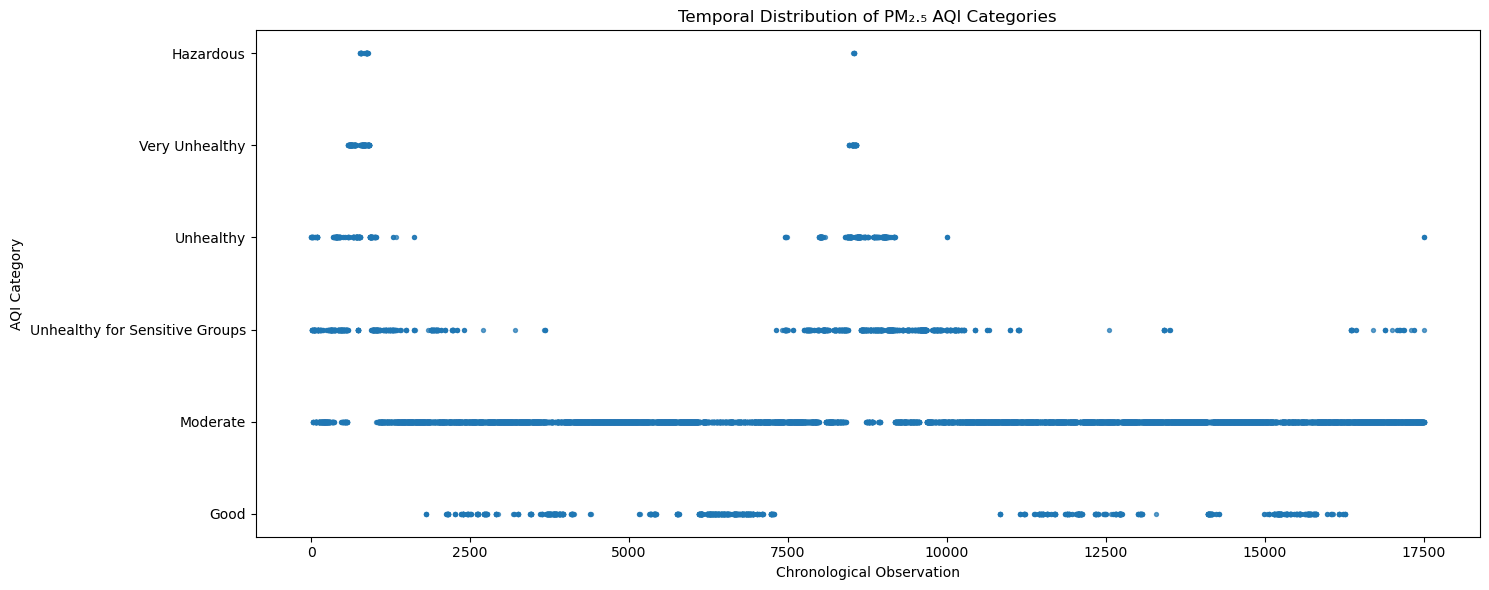

In [44]:
# ============================================================
# 40. VISUALIZE AQI CATEGORIES THROUGH TIME
# ============================================================

category_to_code = {
    "Good": 1,
    "Moderate": 2,
    "Unhealthy for Sensitive Groups": 3,
    "Unhealthy": 4,
    "Very Unhealthy": 5,
    "Hazardous": 6
}

temporal_aqi["Category_Code"] = (
    temporal_aqi["AQI_Category"]
    .map(category_to_code)
)

plt.figure(figsize=(15, 6))

plt.scatter(
    temporal_aqi["Observation"],
    temporal_aqi["Category_Code"],
    s=8,
    alpha=0.7
)

plt.yticks(
    range(1, 7),
    class_order
)

plt.xlabel("Chronological Observation")
plt.ylabel("AQI Category")
plt.title("Temporal Distribution of PM₂.₅ AQI Categories")

plt.tight_layout()
plt.show()

## 10. Identify Suitable Rolling-Forward Evaluation Windows



In [45]:
# ============================================================
# 41. INSPECT SMALLER CHRONOLOGICAL WINDOWS
# ============================================================

WINDOW_SIZE = 500

class_order = [
    "Good",
    "Moderate",
    "Unhealthy for Sensitive Groups",
    "Unhealthy",
    "Very Unhealthy",
    "Hazardous"
]

window_records = []

for start in range(0, len(y), WINDOW_SIZE):

    end = min(start + WINDOW_SIZE, len(y))

    window_y = y.iloc[start:end]

    counts = (
        window_y
        .value_counts()
        .reindex(class_order, fill_value=0)
    )

    window_records.append({
        "Start": start,
        "End": end - 1,
        "Observations": len(window_y),
        "Good": counts["Good"],
        "Moderate": counts["Moderate"],
        "USG": counts["Unhealthy for Sensitive Groups"],
        "Unhealthy": counts["Unhealthy"],
        "Very_Unhealthy": counts["Very Unhealthy"],
        "Hazardous": counts["Hazardous"]
    })

window_summary = pd.DataFrame(window_records)

display(window_summary)

,Start,End,Observations,Good,Moderate,USG,Unhealthy,Very_Unhealthy,Hazardous
0,0,499,500,0,210,194,96,0,0
1,500,999,500,0,28,94,124,217,37
2,1000,1499,500,0,361,126,13,0,0
3,1500,1999,500,4,429,65,2,0,0
4,2000,2499,500,48,429,23,0,0,0
5,2500,2999,500,56,443,1,0,0,0
6,3000,3499,500,22,477,1,0,0,0
7,3500,3999,500,164,332,4,0,0,0
8,4000,4499,500,20,480,0,0,0,0
9,4500,4999,500,0,500,0,0,0,0


In [46]:
# ============================================================
# 42. LOCATE WINDOWS CONTAINING RARE AQI CLASSES
# ============================================================

rare_windows = window_summary[
    (window_summary["Very_Unhealthy"] > 0) |
    (window_summary["Hazardous"] > 0)
].copy()

print("Windows containing Very Unhealthy and/or Hazardous observations:")
print()

display(rare_windows)

Windows containing Very Unhealthy and/or Hazardous observations:



,Start,End,Observations,Good,Moderate,USG,Unhealthy,Very_Unhealthy,Hazardous
1,500,999,500,0,28,94,124,217,37
16,8000,8499,500,0,206,178,109,7,0
17,8500,8999,500,0,66,211,155,61,7


In [47]:
# ============================================================
# 43. FIND WINDOWS CONTAINING BOTH SEVERE CLASSES
# ============================================================

both_severe = window_summary[
    (window_summary["Very_Unhealthy"] > 0) &
    (window_summary["Hazardous"] > 0)
].copy()

print("Windows containing BOTH Very Unhealthy and Hazardous:")
print()

display(both_severe)

Windows containing BOTH Very Unhealthy and Hazardous:



,Start,End,Observations,Good,Moderate,USG,Unhealthy,Very_Unhealthy,Hazardous
1,500,999,500,0,28,94,124,217,37
17,8500,8999,500,0,66,211,155,61,7


## 11. Rolling-Forward Evaluation Design



In [48]:
# ============================================================
# 44. FINAL ROLLING-FORWARD FOLD DESIGN
# ============================================================

INITIAL_TRAIN_SIZE = 2000
TEST_WINDOW_SIZE = 1000

final_rolling_splits = []

for test_start in range(
    INITIAL_TRAIN_SIZE,
    len(y),
    TEST_WINDOW_SIZE
):

    test_end = min(
        test_start + TEST_WINDOW_SIZE,
        len(y)
    )

    # Skip an incomplete final window for now.
    # We will evaluate the final chronological holdout separately.
    if test_end - test_start < TEST_WINDOW_SIZE:
        break

    train_indices = np.arange(
        0,
        test_start
    )

    test_indices = np.arange(
        test_start,
        test_end
    )

    final_rolling_splits.append(
        (train_indices, test_indices)
    )

print("Number of rolling-forward folds:",
      len(final_rolling_splits))

print()

for fold_number, (train_idx, test_idx) in enumerate(
    final_rolling_splits,
    start=1
):

    print(
        f"Fold {fold_number:02d}: "
        f"Train = {len(train_idx):,} | "
        f"Test = {len(test_idx):,} | "
        f"Test range = "
        f"{test_idx[0]}–{test_idx[-1]}"
    )

Number of rolling-forward folds: 15

Fold 01: Train = 2,000 | Test = 1,000 | Test range = 2000–2999
Fold 02: Train = 3,000 | Test = 1,000 | Test range = 3000–3999
Fold 03: Train = 4,000 | Test = 1,000 | Test range = 4000–4999
Fold 04: Train = 5,000 | Test = 1,000 | Test range = 5000–5999
Fold 05: Train = 6,000 | Test = 1,000 | Test range = 6000–6999
Fold 06: Train = 7,000 | Test = 1,000 | Test range = 7000–7999
Fold 07: Train = 8,000 | Test = 1,000 | Test range = 8000–8999
Fold 08: Train = 9,000 | Test = 1,000 | Test range = 9000–9999
Fold 09: Train = 10,000 | Test = 1,000 | Test range = 10000–10999
Fold 10: Train = 11,000 | Test = 1,000 | Test range = 11000–11999
Fold 11: Train = 12,000 | Test = 1,000 | Test range = 12000–12999
Fold 12: Train = 13,000 | Test = 1,000 | Test range = 13000–13999
Fold 13: Train = 14,000 | Test = 1,000 | Test range = 14000–14999
Fold 14: Train = 15,000 | Test = 1,000 | Test range = 15000–15999
Fold 15: Train = 16,000 | Test = 1,000 | Test range = 16000–169

In [49]:
# ============================================================
# 45. VERIFY FINAL ROLLING-FORWARD FOLDS
# ============================================================

for fold_number, (train_idx, test_idx) in enumerate(
    final_rolling_splits,
    start=1
):

    # Training must precede testing
    assert train_idx.max() < test_idx.min()

    # No overlap
    assert len(
        np.intersect1d(train_idx, test_idx)
    ) == 0

    # Training is continuous
    assert np.all(
        np.diff(train_idx) == 1
    )

    # Test is continuous
    assert np.all(
        np.diff(test_idx) == 1
    )

    # Training must contain all six classes
    train_classes = set(
        y.iloc[train_idx].unique()
    )

    assert train_classes == set(class_order), (
        f"Fold {fold_number} training set does not "
        "contain all six AQI classes."
    )

print("✓ All folds preserve chronological ordering.")
print("✓ No train/test observations overlap.")
print("✓ Every training fold contains all six AQI classes.")

✓ All folds preserve chronological ordering.
✓ No train/test observations overlap.
✓ Every training fold contains all six AQI classes.


In [50]:
# ============================================================
# 46. TEST-SET CLASS DISTRIBUTION FOR FINAL FOLDS
# ============================================================

fold_class_summary = []

for fold_number, (_, test_idx) in enumerate(
    final_rolling_splits,
    start=1
):

    fold_y = y.iloc[test_idx]

    counts = (
        fold_y
        .value_counts()
        .reindex(
            class_order,
            fill_value=0
        )
    )

    fold_class_summary.append({
        "Fold": fold_number,
        "Test_Start": test_idx[0],
        "Test_End": test_idx[-1],
        **counts.to_dict()
    })

fold_class_summary = pd.DataFrame(
    fold_class_summary
)

display(fold_class_summary)

,Fold,Test_Start,Test_End,Good,Moderate,Unhealthy for Sensitive Groups,Unhealthy,Very Unhealthy,Hazardous
0,1,2000,2999,104,872,24,0,0,0
1,2,3000,3999,186,809,5,0,0,0
2,3,4000,4999,20,980,0,0,0,0
3,4,5000,5999,60,940,0,0,0,0
4,5,6000,6999,443,557,0,0,0,0
5,6,7000,7999,45,835,102,18,0,0
6,7,8000,8999,0,272,389,264,68,7
7,8,9000,9999,0,515,412,73,0,0
8,9,10000,10999,6,896,95,3,0,0
9,10,11000,11999,103,887,10,0,0,0


In [51]:
# ============================================================
# 47. VERIFY POOLED TEST-SET CLASS COVERAGE
# ============================================================

pooled_test_indices = np.concatenate([
    test_idx
    for _, test_idx in final_rolling_splits
])

pooled_y = y.iloc[pooled_test_indices]

pooled_counts = (
    pooled_y
    .value_counts()
    .reindex(
        class_order,
        fill_value=0
    )
)

print("POOLED ROLLING-FORWARD TEST DISTRIBUTION")
print("=" * 70)

print(
    pd.DataFrame({
        "AQI Category": class_order,
        "Count": pooled_counts.values,
        "Percentage": (
            pooled_counts.values /
            pooled_counts.sum() * 100
        ).round(2)
    }).to_string(index=False)
)

assert (pooled_counts > 0).all()

print("\n✓ All six AQI classes are represented in the pooled test observations.")

POOLED ROLLING-FORWARD TEST DISTRIBUTION
                  AQI Category  Count  Percentage
                          Good   1435        9.57
                      Moderate  12066       80.44
Unhealthy for Sensitive Groups   1066        7.11
                     Unhealthy    358        2.39
                Very Unhealthy     68        0.45
                     Hazardous      7        0.05

✓ All six AQI classes are represented in the pooled test observations.


## 12. Class-Weighted SVM-RBF Baseline



The baseline model uses:

- RBF kernel
- C = 1.0
- gamma = "scale"
- class_weight = "balanced"

Hyperparameter optimisation will be performed separately after establishing
the baseline.

In [52]:
# ============================================================
# 48. CLASS-WEIGHTED SVM-RBF BASELINE
# ============================================================

def create_weighted_svm():
    """
    Create a leakage-safe class-weighted SVM-RBF pipeline.

    StandardScaler is fitted only on the training data of each fold.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svm",
            SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale",
                class_weight="balanced",
                random_state=RANDOM_STATE
            )
        )
    ])


print("Class-weighted SVM-RBF pipeline defined.")

Class-weighted SVM-RBF pipeline defined.


In [53]:
# ============================================================
# 49. TEST CLASS-WEIGHTED SVM ON FOLD 1
# ============================================================

train_idx, test_idx = final_rolling_splits[0]

X_train = X_full.iloc[train_idx]
X_test = X_full.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training observations:", len(X_train))
print("Testing observations :", len(X_test))
print("Training features    :", X_train.shape[1])

print("\nTraining class distribution:")
print(y_train.value_counts().reindex(
    class_order,
    fill_value=0
))

print("\nTest class distribution:")
print(y_test.value_counts().reindex(
    class_order,
    fill_value=0
))

Training observations: 2000
Testing observations : 1000
Training features    : 28

Training class distribution:
AQI_Category
Good                                 4
Moderate                          1028
Unhealthy for Sensitive Groups     479
Unhealthy                          235
Very Unhealthy                     217
Hazardous                           37
Name: count, dtype: int64

Test class distribution:
AQI_Category
Good                              104
Moderate                          872
Unhealthy for Sensitive Groups     24
Unhealthy                           0
Very Unhealthy                      0
Hazardous                           0
Name: count, dtype: int64


In [54]:
# ============================================================
# 50. TRAIN AND TEST FOLD 1
# ============================================================

baseline_model = create_weighted_svm()

baseline_model.fit(
    X_train,
    y_train
)

fold1_predictions = baseline_model.predict(
    X_test
)

print("Fold 1 prediction completed.")
print("Number of predictions:", len(fold1_predictions))

assert len(fold1_predictions) == len(y_test)

print("\nPredicted class distribution:")
print(
    pd.Series(fold1_predictions)
    .value_counts()
    .reindex(
        class_order,
        fill_value=0
    )
)

Fold 1 prediction completed.
Number of predictions: 1000

Predicted class distribution:
Good                               46
Moderate                          938
Unhealthy for Sensitive Groups     16
Unhealthy                           0
Very Unhealthy                      0
Hazardous                           0
Name: count, dtype: int64


In [55]:
# ============================================================
# 51. FOLD 1 BASELINE METRICS
# ============================================================

fold1_accuracy = accuracy_score(
    y_test,
    fold1_predictions
)

fold1_precision = precision_score(
    y_test,
    fold1_predictions,
    labels=class_order,
    average="macro",
    zero_division=0
)

fold1_recall = recall_score(
    y_test,
    fold1_predictions,
    labels=class_order,
    average="macro",
    zero_division=0
)

fold1_f1 = f1_score(
    y_test,
    fold1_predictions,
    labels=class_order,
    average="macro",
    zero_division=0
)

fold1_weighted_f1 = f1_score(
    y_test,
    fold1_predictions,
    labels=class_order,
    average="weighted",
    zero_division=0
)

fold1_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1"
    ],
    "Score": [
        fold1_accuracy,
        fold1_precision,
        fold1_recall,
        fold1_f1,
        fold1_weighted_f1
    ]
})

fold1_results["Score"] = (
    fold1_results["Score"] * 100
).round(2)

display(fold1_results)

,Metric,Score
0,Accuracy,85.20
1,Macro Precision,31.21
2,Macro Recall,26.19
3,Macro F1,27.91
4,Weighted F1,82.74


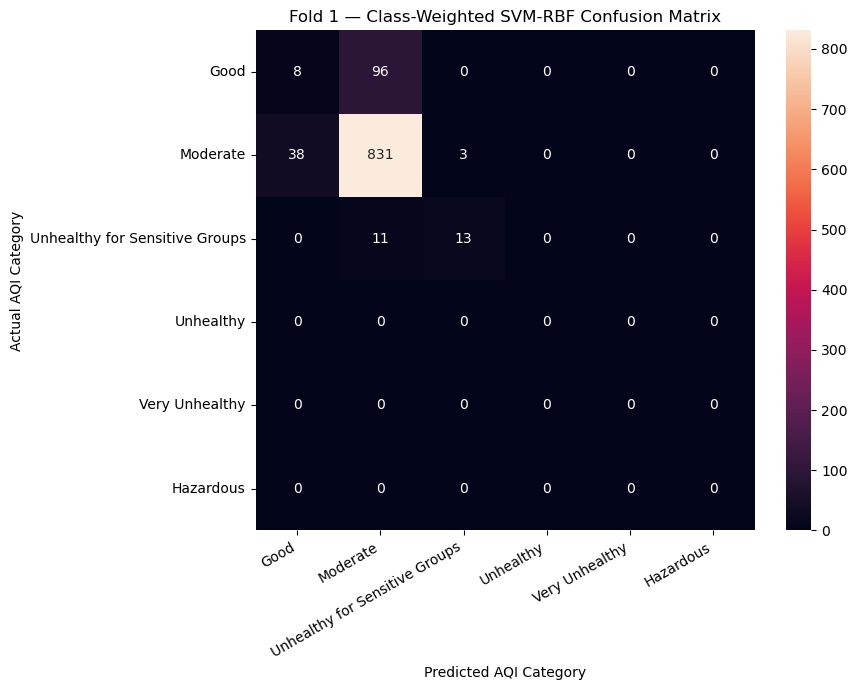

In [56]:
# ============================================================
# 52. FOLD 1 CONFUSION MATRIX
# ============================================================

cm_fold1 = confusion_matrix(
    y_test,
    fold1_predictions,
    labels=class_order
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_fold1,
    annot=True,
    fmt="d",
    xticklabels=class_order,
    yticklabels=class_order
)

plt.xlabel("Predicted AQI Category")
plt.ylabel("Actual AQI Category")
plt.title("Fold 1 — Class-Weighted SVM-RBF Confusion Matrix")

plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [57]:
# ============================================================
# 51. FOLD 1 METRICS
# ============================================================

# Classes actually present in this test window
fold1_present_classes = sorted(
    y_test.unique(),
    key=class_order.index
)

print("Classes present in Fold 1 test set:")
print(fold1_present_classes)

fold1_accuracy = accuracy_score(
    y_test,
    fold1_predictions
)

fold1_precision = precision_score(
    y_test,
    fold1_predictions,
    labels=fold1_present_classes,
    average="macro",
    zero_division=0
)

fold1_recall = recall_score(
    y_test,
    fold1_predictions,
    labels=fold1_present_classes,
    average="macro",
    zero_division=0
)

fold1_f1 = f1_score(
    y_test,
    fold1_predictions,
    labels=fold1_present_classes,
    average="macro",
    zero_division=0
)

fold1_weighted_f1 = f1_score(
    y_test,
    fold1_predictions,
    labels=fold1_present_classes,
    average="weighted",
    zero_division=0
)

fold1_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1"
    ],
    "Score": [
        fold1_accuracy,
        fold1_precision,
        fold1_recall,
        fold1_f1,
        fold1_weighted_f1
    ]
})

fold1_results["Score"] = (
    fold1_results["Score"] * 100
).round(2)

display(fold1_results)

Classes present in Fold 1 test set:
['Good', 'Moderate', 'Unhealthy for Sensitive Groups']


,Metric,Score
0,Accuracy,85.20
1,Macro Precision,62.41
2,Macro Recall,52.39
3,Macro F1,55.83
4,Weighted F1,82.74


In [58]:
# ============================================================
# 53. ROLLING-FORWARD CLASS-WEIGHTED SVM
# FULL FEATURES
# ============================================================

full_weighted_predictions = []
full_weighted_actual = []
full_weighted_fold_results = []

for fold_number, (train_idx, test_idx) in enumerate(
    final_rolling_splits,
    start=1
):

    print(f"Running Fold {fold_number:02d}...")

    X_train = X_full.iloc[train_idx]
    X_test = X_full.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Fresh pipeline for every fold
    model = create_weighted_svm()

    # Fit only on historical training observations
    model.fit(
        X_train,
        y_train
    )

    # Predict the future test window
    predictions = model.predict(
        X_test
    )

    # Store pooled out-of-fold predictions
    full_weighted_predictions.extend(
        predictions
    )

    full_weighted_actual.extend(
        y_test.values
    )

    # --------------------------------------------------------
    # Fold-specific metrics
    # --------------------------------------------------------

    # Only classes actually present in this test window
    present_classes = sorted(
        y_test.unique(),
        key=class_order.index
    )

    fold_result = {
        "Fold": fold_number,
        "Test_Start": test_idx[0],
        "Test_End": test_idx[-1],
        "Test_Size": len(test_idx),

        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Macro_Precision": precision_score(
            y_test,
            predictions,
            labels=present_classes,
            average="macro",
            zero_division=0
        ),

        "Macro_Recall": recall_score(
            y_test,
            predictions,
            labels=present_classes,
            average="macro",
            zero_division=0
        ),

        "Macro_F1": f1_score(
            y_test,
            predictions,
            labels=present_classes,
            average="macro",
            zero_division=0
        ),

        "Weighted_F1": f1_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Classes_Present": ", ".join(
            present_classes
        )
    }

    full_weighted_fold_results.append(
        fold_result
    )

print("\n✓ Full-feature class-weighted SVM evaluation completed.")

Running Fold 01...
Running Fold 02...
Running Fold 03...
Running Fold 04...
Running Fold 05...
Running Fold 06...
Running Fold 07...
Running Fold 08...
Running Fold 09...
Running Fold 10...
Running Fold 11...
Running Fold 12...
Running Fold 13...
Running Fold 14...
Running Fold 15...

✓ Full-feature class-weighted SVM evaluation completed.


In [59]:
# ============================================================
# 54. FOLD-BY-FOLD BASELINE RESULTS
# ============================================================

full_weighted_fold_results = pd.DataFrame(
    full_weighted_fold_results
)

display(
    full_weighted_fold_results.round(4)
)

,Fold,Test_Start,Test_End,Test_Size,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Classes_Present
0,1,2000,2999,1000,0.852,0.6241,0.5239,0.5583,0.8274,"Good, Moderate, Unhealthy for Sensitive Groups"
1,2,3000,3999,1000,0.655,0.6185,0.3541,0.3974,0.6523,"Good, Moderate, Unhealthy for Sensitive Groups"
2,3,4000,4999,1000,0.376,0.5155,0.6816,0.2966,0.5235,"Good, Moderate"
3,4,5000,5999,1000,0.921,0.6846,0.7707,0.7170,0.9284,"Good, Moderate"
4,5,6000,6999,1000,0.829,0.8302,0.8222,0.8249,0.8280,"Good, Moderate"
5,6,7000,7999,1000,0.749,0.6241,0.9141,0.6826,0.7880,"Good, Moderate, Unhealthy for Sensitive Groups..."
6,7,8000,8999,1000,0.800,0.7360,0.7362,0.7184,0.7990,"Moderate, Unhealthy for Sensitive Groups, Unhe..."
7,8,9000,9999,1000,0.854,0.8818,0.9003,0.8782,0.8536,"Moderate, Unhealthy for Sensitive Groups, Unhe..."
8,9,10000,10999,1000,0.938,0.7512,0.8952,0.8033,0.9438,"Good, Moderate, Unhealthy for Sensitive Groups..."
9,10,11000,11999,1000,0.895,0.8018,0.9577,0.8506,0.9090,"Good, Moderate, Unhealthy for Sensitive Groups"


In [60]:
# ============================================================
# 56. POOLED ROLLING-FORWARD PERFORMANCE
# ============================================================

full_weighted_actual = np.array(
    full_weighted_actual
)

full_weighted_predictions = np.array(
    full_weighted_predictions
)

pooled_baseline_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1"
    ],
    "Score": [
        accuracy_score(
            full_weighted_actual,
            full_weighted_predictions
        ),
        precision_score(
            full_weighted_actual,
            full_weighted_predictions,
            labels=class_order,
            average="macro",
            zero_division=0
        ),
        recall_score(
            full_weighted_actual,
            full_weighted_predictions,
            labels=class_order,
            average="macro",
            zero_division=0
        ),
        f1_score(
            full_weighted_actual,
            full_weighted_predictions,
            labels=class_order,
            average="macro",
            zero_division=0
        ),
        f1_score(
            full_weighted_actual,
            full_weighted_predictions,
            labels=class_order,
            average="weighted",
            zero_division=0
        )
    ]
})

pooled_baseline_metrics["Score"] *= 100

pooled_baseline_metrics["Score"] = (
    pooled_baseline_metrics["Score"].round(2)
)

display(pooled_baseline_metrics)

,Metric,Score
0,Accuracy,82.54
1,Macro Precision,66.23
2,Macro Recall,77.91
3,Macro F1,70.25
4,Weighted F1,84.29


In [61]:
# ============================================================
# 57. POOLED CLASS-WISE BASELINE PERFORMANCE
# ============================================================

baseline_report = classification_report(
    full_weighted_actual,
    full_weighted_predictions,
    labels=class_order,
    target_names=class_order,
    output_dict=True,
    zero_division=0
)

baseline_class_report = pd.DataFrame(
    baseline_report
).T

baseline_class_report = baseline_class_report.loc[
    class_order,
    [
        "precision",
        "recall",
        "f1-score",
        "support"
    ]
]

baseline_class_report = (
    baseline_class_report
    .rename(columns={
        "precision": "Precision",
        "recall": "Recall",
        "f1-score": "F1",
        "support": "Support"
    })
)

baseline_class_report[
    ["Precision", "Recall", "F1"]
] *= 100

baseline_class_report[
    ["Precision", "Recall", "F1"]
] = (
    baseline_class_report[
        ["Precision", "Recall", "F1"]
    ].round(2)
)

display(baseline_class_report)

,Precision,Recall,F1,Support
Good,38.25,71.71,49.89,1435.0
Moderate,95.83,82.82,88.85,12066.0
Unhealthy for Sensitive Groups,70.09,92.31,79.68,1066.0
Unhealthy,84.70,86.59,85.64,358.0
Very Unhealthy,58.49,91.18,71.26,68.0
Hazardous,50.00,42.86,46.15,7.0


In [62]:
# ============================================================
# SMOTE EXPERIMENT — STEP 1
# Inspect Fold 1 Training Class Distribution
# ============================================================

# Define the first rolling-forward split
INITIAL_TRAIN_SIZE = 2000
TEST_SIZE = 1000

train_idx = np.arange(0, INITIAL_TRAIN_SIZE)
test_idx = np.arange(INITIAL_TRAIN_SIZE, INITIAL_TRAIN_SIZE + TEST_SIZE)

y_train_fold1 = y.iloc[train_idx]

# Class distribution
fold1_distribution = (
    y_train_fold1
    .value_counts()
    .reindex(aqi_breakpoints["Category"])
    .fillna(0)
    .astype(int)
)

# Percentage distribution
fold1_percentage = (
    y_train_fold1
    .value_counts(normalize=True)
    .reindex(aqi_breakpoints["Category"])
    .fillna(0)
    .mul(100)
)

# Imbalance ratio relative to the majority class
majority_count = fold1_distribution.max()

fold1_imbalance_ratio = (
    majority_count / fold1_distribution
).round(2)

fold1_smote_inspection = pd.DataFrame({
    "Class": fold1_distribution.index,
    "Count": fold1_distribution.values,
    "Percentage (%)": fold1_percentage.values.round(2),
    "Imbalance Ratio": fold1_imbalance_ratio.values
})

print("Fold 1 Training Class Distribution")
print("=" * 60)
display(fold1_smote_inspection)

Fold 1 Training Class Distribution


,Class,Count,Percentage (%),Imbalance Ratio
0,Good,4,0.20,257.00
1,Moderate,1028,51.40,1.00
2,Unhealthy for Sensitive Groups,479,23.95,2.15
3,Unhealthy,235,11.75,4.37
4,Very Unhealthy,217,10.85,4.74
5,Hazardous,37,1.85,27.78


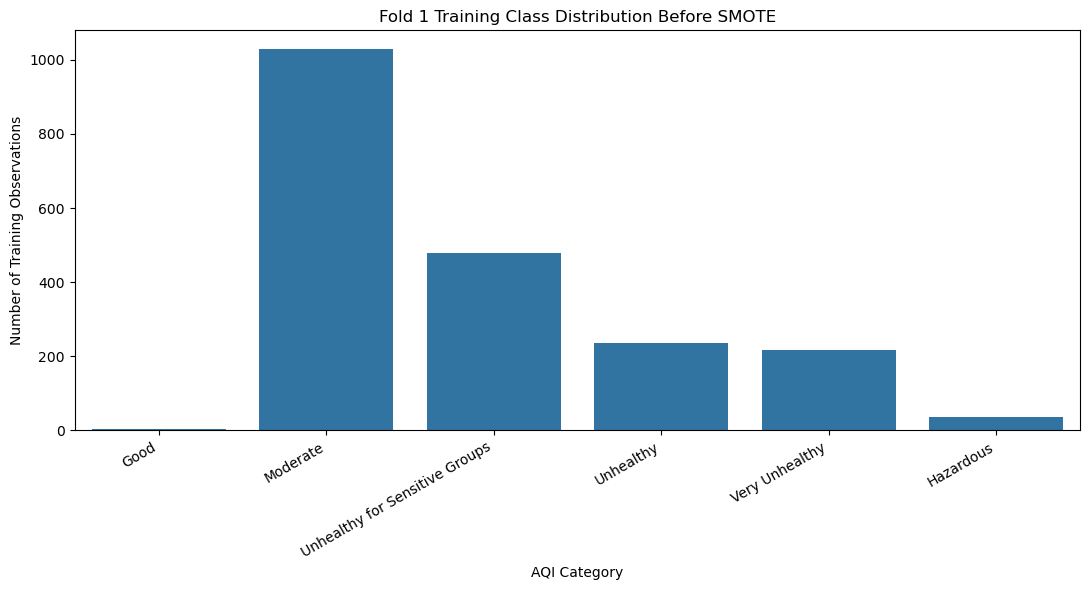

In [63]:
# ============================================================
# Visualize Fold 1 Training Class Imbalance
# ============================================================

plt.figure(figsize=(11, 6))

sns.barplot(
    data=fold1_smote_inspection,
    x="Class",
    y="Count"
)

plt.title("Fold 1 Training Class Distribution Before SMOTE")
plt.xlabel("AQI Category")
plt.ylabel("Number of Training Observations")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [64]:
# ============================================================
# SMOTE EXPERIMENT — STEP 2
# Inspect Training-Class Availability Across All Folds
# ============================================================

class_order = aqi_breakpoints["Category"].tolist()

fold_training_distributions = []

for fold in range(15):

    train_end = INITIAL_TRAIN_SIZE + fold * TEST_SIZE

    train_idx = np.arange(0, train_end)
    y_train = y.iloc[train_idx]

    counts = (
        y_train
        .value_counts()
        .reindex(class_order)
        .fillna(0)
        .astype(int)
    )

    row = {
        "Fold": fold + 1,
        "Training End": train_end - 1
    }

    for cls in class_order:
        row[cls] = counts[cls]

    fold_training_distributions.append(row)

training_distribution_df = pd.DataFrame(fold_training_distributions)

display(training_distribution_df)

,Fold,Training End,Good,Moderate,Unhealthy for Sensitive Groups,Unhealthy,Very Unhealthy,Hazardous
0,1,1999,4,1028,479,235,217,37
1,2,2999,108,1900,503,235,217,37
2,3,3999,294,2709,508,235,217,37
3,4,4999,314,3689,508,235,217,37
4,5,5999,374,4629,508,235,217,37
5,6,6999,817,5186,508,235,217,37
6,7,7999,862,6021,610,253,217,37
7,8,8999,862,6293,999,517,285,44
8,9,9999,862,6808,1411,590,285,44
9,10,10999,868,7704,1506,593,285,44


In [65]:
# ============================================================
# Minimum Training Support Across All Rolling Folds
# ============================================================

min_training_counts = (
    training_distribution_df[class_order]
    .min()
    .sort_values()
)

max_training_counts = (
    training_distribution_df[class_order]
    .max()
    .sort_values(ascending=False)
)

smote_support_summary = pd.DataFrame({
    "Minimum Training Count": min_training_counts,
    "Maximum Training Count": max_training_counts
})

print("Training-Class Support Across All 15 Rolling Folds")
print("=" * 65)

display(smote_support_summary)

Training-Class Support Across All 15 Rolling Folds


,Minimum Training Count,Maximum Training Count
Good,4,1419
Hazardous,37,44
Moderate,1028,12131
Unhealthy,235,593
Unhealthy for Sensitive Groups,479,1528
Very Unhealthy,217,285


In [66]:
# ============================================================
# Worst-Case Imbalance Ratio Across Training Folds
# ============================================================

imbalance_records = []

for _, row in training_distribution_df.iterrows():

    majority_count = max(row[cls] for cls in class_order)

    for cls in class_order:
        count = row[cls]

        imbalance_records.append({
            "Fold": row["Fold"],
            "Class": cls,
            "Count": count,
            "Imbalance Ratio": (
                majority_count / count if count > 0 else np.inf
            )
        })

imbalance_df = pd.DataFrame(imbalance_records)

worst_case_imbalance = (
    imbalance_df
    .sort_values("Imbalance Ratio", ascending=False)
    .head(10)
)

print("Worst-Case Training Imbalance Across Rolling Folds")
print("=" * 65)

display(worst_case_imbalance)

Worst-Case Training Imbalance Across Rolling Folds


,Fold,Class,Count,Imbalance Ratio
89,15,Hazardous,44,275.704545
83,14,Hazardous,44,258.204545
0,1,Good,4,257.000000
77,13,Hazardous,44,236.818182
71,12,Hazardous,44,214.840909
65,11,Hazardous,44,195.250000
59,10,Hazardous,44,175.090909
41,7,Hazardous,37,162.729730
53,9,Hazardous,44,154.727273
47,8,Hazardous,44,143.022727


In [67]:
# ============================================================
# SMOTE EXPERIMENT — STEP 3
# Determine Safe SMOTE Neighbourhood and Eligible Classes
# ============================================================

SMOTE_K_NEIGHBORS = 3

# A class must contain at least k_neighbors + 1 observations
# in every training fold in which SMOTE is applied.
minimum_required_samples = SMOTE_K_NEIGHBORS + 1

smote_eligibility = pd.DataFrame({
    "Class": class_order,
    "Minimum Training Count": [
        training_distribution_df[cls].min()
        for cls in class_order
    ]
})

smote_eligibility["Eligible for SMOTE"] = (
    smote_eligibility["Minimum Training Count"]
    >= minimum_required_samples
)

print("SMOTE Eligibility Check")
print("=" * 60)
print(f"SMOTE k_neighbors: {SMOTE_K_NEIGHBORS}")
print(f"Minimum observations required: {minimum_required_samples}")
print()

display(smote_eligibility)

SMOTE Eligibility Check
SMOTE k_neighbors: 3
Minimum observations required: 4



,Class,Minimum Training Count,Eligible for SMOTE
0,Good,4,True
1,Moderate,1028,True
2,Unhealthy for Sensitive Groups,479,True
3,Unhealthy,235,True
4,Very Unhealthy,217,True
5,Hazardous,37,True


In [68]:
# ============================================================
# Identify Classes Requiring Special Treatment
# ============================================================

eligible_classes = smote_eligibility.loc[
    smote_eligibility["Eligible for SMOTE"],
    "Class"
].tolist()

ineligible_classes = smote_eligibility.loc[
    ~smote_eligibility["Eligible for SMOTE"],
    "Class"
].tolist()

print("Eligible classes:")
for cls in eligible_classes:
    print(f"  ✓ {cls}")

print("\nClasses requiring special treatment:")
for cls in ineligible_classes:
    print(f"  ! {cls}")

Eligible classes:
  ✓ Good
  ✓ Moderate
  ✓ Unhealthy for Sensitive Groups
  ✓ Unhealthy
  ✓ Very Unhealthy
  ✓ Hazardous

Classes requiring special treatment:


In [69]:
# ============================================================
# SMOTE EXPERIMENT — STEP 4
# Compare Potential Sampling Strategies
# ============================================================

def proposed_smote_targets(y_train, strategy="half_majority"):
    """
    Calculate proposed SMOTE target counts without actually
    generating synthetic observations.
    """

    counts = y_train.value_counts()
    majority_count = counts.max()

    targets = counts.to_dict()

    if strategy == "full_balance":

        # Balance all minority classes to the majority class
        for cls in counts.index:
            if counts[cls] < majority_count:
                targets[cls] = majority_count

    elif strategy == "half_majority":

        # Raise minority classes to approximately 50% of majority
        target_level = int(np.floor(0.50 * majority_count))

        for cls in counts.index:
            if counts[cls] < target_level:
                targets[cls] = target_level

    elif strategy == "controlled":

        # Conservative fixed upper targets
        controlled_targets = {
            "Good": 100,
            "Unhealthy for Sensitive Groups": 500,
            "Unhealthy": 500,
            "Very Unhealthy": 500,
            "Hazardous": 100
        }

        for cls, target in controlled_targets.items():

            current_count = counts.get(cls, 0)

            # Do not oversample extremely sparse classes
            # until they have at least 10 real observations.
            if current_count >= 10 and current_count < target:
                targets[cls] = target

    return pd.Series(targets).reindex(class_order).fillna(0).astype(int)


# Inspect Fold 1
y_train_fold1 = y.iloc[:INITIAL_TRAIN_SIZE]

strategies = {
    "Full Balance": "full_balance",
    "50% of Majority": "half_majority",
    "Controlled": "controlled"
}

comparison_rows = []

original_counts = (
    y_train_fold1
    .value_counts()
    .reindex(class_order)
    .fillna(0)
    .astype(int)
)

for strategy_name, strategy_code in strategies.items():

    targets = proposed_smote_targets(
        y_train_fold1,
        strategy=strategy_code
    )

    for cls in class_order:

        before = original_counts[cls]
        target = targets[cls]

        comparison_rows.append({
            "Strategy": strategy_name,
            "Class": cls,
            "Before": before,
            "Target": target,
            "Synthetic Observations": max(0, target - before)
        })

smote_strategy_comparison = pd.DataFrame(comparison_rows)

display(smote_strategy_comparison)

,Strategy,Class,Before,Target,Synthetic Observations
0,Full Balance,Good,4,1028,1024
1,Full Balance,Moderate,1028,1028,0
2,Full Balance,Unhealthy for Sensitive Groups,479,1028,549
3,Full Balance,Unhealthy,235,1028,793
4,Full Balance,Very Unhealthy,217,1028,811
5,Full Balance,Hazardous,37,1028,991
6,50% of Majority,Good,4,514,510
7,50% of Majority,Moderate,1028,1028,0
8,50% of Majority,Unhealthy for Sensitive Groups,479,514,35
9,50% of Majority,Unhealthy,235,514,279


In [70]:
# ============================================================
# Summarize Synthetic Data Generated by Each Strategy
# ============================================================

synthetic_summary = (
    smote_strategy_comparison
    .groupby("Strategy")["Synthetic Observations"]
    .sum()
    .reset_index()
    .sort_values("Synthetic Observations")
)

print("Potential Synthetic Observations — Fold 1")
print("=" * 60)

display(synthetic_summary)

Potential Synthetic Observations — Fold 1


,Strategy,Synthetic Observations
1,Controlled,632
0,50% of Majority,1598
2,Full Balance,4168


In [71]:
# ============================================================
# SMOTE EXPERIMENT — STEP 5
# Apply Controlled SMOTE to Fold 1 Training Data
# ============================================================

from imblearn.over_sampling import SMOTE

SMOTE_K_NEIGHBORS = 3

def get_controlled_sampling_strategy(y_train):
    """
    Define controlled SMOTE target counts.

    The target is applied only when the current class count
    is below the specified target and sufficiently large for
    reliable SMOTE generation.
    """

    counts = y_train.value_counts()

    desired_targets = {
        "Good": 100,
        "Unhealthy for Sensitive Groups": 500,
        "Unhealthy": 500,
        "Very Unhealthy": 500,
        "Hazardous": 100
    }

    sampling_strategy = {}

    for cls, target in desired_targets.items():

        current_count = counts.get(cls, 0)

        # Only oversample classes that:
        # 1. exist in the training data
        # 2. have at least 10 real observations
        # 3. are below the desired target
        if (
            current_count >= 10
            and current_count < target
        ):
            sampling_strategy[cls] = target

    return sampling_strategy


# Fold 1 training data
X_train_fold1 = X_full.iloc[:INITIAL_TRAIN_SIZE].copy()
y_train_fold1 = y.iloc[:INITIAL_TRAIN_SIZE].copy()

# Determine controlled sampling targets
sampling_strategy_fold1 = get_controlled_sampling_strategy(
    y_train_fold1
)

print("Fold 1 Controlled SMOTE Sampling Strategy")
print("=" * 60)

for cls, target in sampling_strategy_fold1.items():
    print(
        f"{cls}: "
        f"{y_train_fold1.value_counts()[cls]} → {target}"
    )

# Apply SMOTE
smote = SMOTE(
    sampling_strategy=sampling_strategy_fold1,
    k_neighbors=SMOTE_K_NEIGHBORS,
    random_state=RANDOM_STATE
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_fold1,
    y_train_fold1
)

print("\nOriginal training shape:", X_train_fold1.shape)
print("After SMOTE shape:", X_train_smote.shape)

Fold 1 Controlled SMOTE Sampling Strategy
Unhealthy for Sensitive Groups: 479 → 500
Unhealthy: 235 → 500
Very Unhealthy: 217 → 500
Hazardous: 37 → 100

Original training shape: (2000, 28)
After SMOTE shape: (2632, 28)


In [72]:
# ============================================================
# Verify Fold 1 SMOTE Output
# ============================================================

before_counts = (
    y_train_fold1
    .value_counts()
    .reindex(class_order)
    .fillna(0)
    .astype(int)
)

after_counts = (
    pd.Series(y_train_smote)
    .value_counts()
    .reindex(class_order)
    .fillna(0)
    .astype(int)
)

smote_verification = pd.DataFrame({
    "Class": class_order,
    "Before SMOTE": before_counts.values,
    "After SMOTE": after_counts.values,
    "Synthetic Added": (
        after_counts.values - before_counts.values
    )
})

print("Fold 1 Training Distribution: Before vs After SMOTE")
print("=" * 70)

display(smote_verification)

Fold 1 Training Distribution: Before vs After SMOTE


,Class,Before SMOTE,After SMOTE,Synthetic Added
0,Good,4,4,0
1,Moderate,1028,1028,0
2,Unhealthy for Sensitive Groups,479,500,21
3,Unhealthy,235,500,265
4,Very Unhealthy,217,500,283
5,Hazardous,37,100,63


In [73]:
# ============================================================
# Verify Test Data Remains Untouched
# ============================================================

X_test_fold1 = X_full.iloc[
    INITIAL_TRAIN_SIZE:
    INITIAL_TRAIN_SIZE + TEST_SIZE
].copy()

y_test_fold1 = y.iloc[
    INITIAL_TRAIN_SIZE:
    INITIAL_TRAIN_SIZE + TEST_SIZE
].copy()

print("Test set shape:", X_test_fold1.shape)

print("\nTest class distribution:")
display(
    y_test_fold1
    .value_counts()
    .reindex(class_order)
    .fillna(0)
    .astype(int)
    .rename("Count")
    .to_frame()
)

Test set shape: (1000, 28)

Test class distribution:


,Count
AQI_Category,
Good,104
Moderate,872
Unhealthy for Sensitive Groups,24
Unhealthy,0
Very Unhealthy,0
Hazardous,0


In [74]:
# ============================================================
# SMOTE-SVM — COMPLETE 15-FOLD ROLLING-FORWARD EVALUATION
# Full Feature Dataset
# ============================================================

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

SMOTE_K_NEIGHBORS = 3

# Store fold-level results
smote_fold_results = []

# Store pooled out-of-fold predictions
smote_oof_predictions = []
smote_oof_actuals = []

# Store SMOTE training distributions for verification
smote_training_distributions = []

print("=" * 75)
print("SMOTE-SVM ROLLING-FORWARD EVALUATION — FULL FEATURE DATASET")
print("=" * 75)

for fold in range(15):

    # --------------------------------------------------------
    # Define chronological train/test indices
    # --------------------------------------------------------
    train_end = INITIAL_TRAIN_SIZE + fold * TEST_SIZE
    test_start = train_end
    test_end = test_start + TEST_SIZE

    train_idx = np.arange(0, train_end)
    test_idx = np.arange(test_start, test_end)

    X_train = X_full.iloc[train_idx].copy()
    y_train = y.iloc[train_idx].copy()

    X_test = X_full.iloc[test_idx].copy()
    y_test = y.iloc[test_idx].copy()

    # --------------------------------------------------------
    # Determine controlled SMOTE targets from training data
    # --------------------------------------------------------
    sampling_strategy = get_controlled_sampling_strategy(y_train)

    # --------------------------------------------------------
    # Create fold-specific pipeline
    #
    # Scaling -> SMOTE -> SVM
    #
    # class_weight=None because SMOTE is the imbalance
    # correction being evaluated in this experiment.
    # --------------------------------------------------------
    smote_svm = ImbPipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "smote",
            SMOTE(
                sampling_strategy=sampling_strategy,
                k_neighbors=SMOTE_K_NEIGHBORS,
                random_state=RANDOM_STATE
            )
        ),
        (
            "svm",
            SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale",
                class_weight=None,
                random_state=RANDOM_STATE
            )
        )
    ])

    # --------------------------------------------------------
    # Fit ONLY on chronological training data
    # --------------------------------------------------------
    smote_svm.fit(X_train, y_train)

    # --------------------------------------------------------
    # Predict untouched future test data
    # --------------------------------------------------------
    y_pred = smote_svm.predict(X_test)

    # --------------------------------------------------------
    # Fold-level metrics
    #
    # Only classes actually present in the test fold are
    # included in fold-level macro metrics.
    # --------------------------------------------------------
    present_classes = sorted(pd.unique(y_test))

    fold_accuracy = accuracy_score(y_test, y_pred)

    fold_precision = precision_score(
        y_test,
        y_pred,
        labels=present_classes,
        average="macro",
        zero_division=0
    )

    fold_recall = recall_score(
        y_test,
        y_pred,
        labels=present_classes,
        average="macro",
        zero_division=0
    )

    fold_f1 = f1_score(
        y_test,
        y_pred,
        labels=present_classes,
        average="macro",
        zero_division=0
    )

    fold_weighted_f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    smote_fold_results.append({
        "Fold": fold + 1,
        "Train End": train_end - 1,
        "Test Start": test_start,
        "Test End": test_end - 1,
        "Accuracy": fold_accuracy,
        "Macro Precision": fold_precision,
        "Macro Recall": fold_recall,
        "Macro F1": fold_f1,
        "Weighted F1": fold_weighted_f1
    })

    # --------------------------------------------------------
    # Store pooled OOF predictions
    # --------------------------------------------------------
    smote_oof_actuals.extend(y_test.tolist())
    smote_oof_predictions.extend(y_pred.tolist())

    # --------------------------------------------------------
    # Record post-SMOTE training distribution
    # --------------------------------------------------------
    y_resampled = smote_svm.named_steps["smote"].fit_resample(
        smote_svm.named_steps["scaler"].transform(X_train),
        y_train
    )[1]

    resampled_counts = (
        pd.Series(y_resampled)
        .value_counts()
        .reindex(class_order)
        .fillna(0)
        .astype(int)
    )

    distribution_row = {
        "Fold": fold + 1
    }

    for cls in class_order:
        distribution_row[cls] = resampled_counts[cls]

    smote_training_distributions.append(distribution_row)

    # --------------------------------------------------------
    # Progress output
    # --------------------------------------------------------
    print(
        f"Fold {fold + 1:02d}/15 | "
        f"Train: {train_end:,} | "
        f"Test: {test_start:,}-{test_end - 1:,} | "
        f"Accuracy: {fold_accuracy:.4f} | "
        f"Macro F1: {fold_f1:.4f}"
    )

# Convert results to DataFrames
smote_fold_results_df = pd.DataFrame(smote_fold_results)
smote_training_distributions_df = pd.DataFrame(
    smote_training_distributions
)

print("\n" + "=" * 75)
print("15-FOLD SMOTE-SVM EVALUATION COMPLETED")
print("=" * 75)

display(smote_fold_results_df)

SMOTE-SVM ROLLING-FORWARD EVALUATION — FULL FEATURE DATASET
Fold 01/15 | Train: 2,000 | Test: 2,000-2,999 | Accuracy: 0.8890 | Macro F1: 0.5898
Fold 02/15 | Train: 3,000 | Test: 3,000-3,999 | Accuracy: 0.8090 | Macro F1: 0.2981
Fold 03/15 | Train: 4,000 | Test: 4,000-4,999 | Accuracy: 0.8170 | Macro F1: 0.4653
Fold 04/15 | Train: 5,000 | Test: 5,000-5,999 | Accuracy: 0.8880 | Macro F1: 0.5809
Fold 05/15 | Train: 6,000 | Test: 6,000-6,999 | Accuracy: 0.5570 | Macro F1: 0.3577
Fold 06/15 | Train: 7,000 | Test: 7,000-7,999 | Accuracy: 0.9230 | Macro F1: 0.8400
Fold 07/15 | Train: 8,000 | Test: 8,000-8,999 | Accuracy: 0.8710 | Macro F1: 0.7481
Fold 08/15 | Train: 9,000 | Test: 9,000-9,999 | Accuracy: 0.9540 | Macro F1: 0.9568
Fold 09/15 | Train: 10,000 | Test: 10,000-10,999 | Accuracy: 0.9710 | Macro F1: 0.7168
Fold 10/15 | Train: 11,000 | Test: 11,000-11,999 | Accuracy: 0.9130 | Macro F1: 0.7357
Fold 11/15 | Train: 12,000 | Test: 12,000-12,999 | Accuracy: 0.9470 | Macro F1: 0.5813
Fold 12

,Fold,Train End,Test Start,Test End,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,1,1999,2000,2999,0.889,0.629027,0.569444,0.589810,0.839723
1,2,2999,3000,3999,0.809,0.269667,0.333333,0.298139,0.723583
2,3,3999,4000,4999,0.817,0.498647,0.490306,0.465348,0.881607
3,4,4999,5000,5999,0.888,0.571221,0.597163,0.580939,0.896609
4,5,5999,6000,6999,0.557,0.278500,0.500000,0.357739,0.398522
5,6,6999,7000,7999,0.923,0.788353,0.928658,0.840009,0.927820
6,7,7999,8000,8999,0.871,0.758970,0.762887,0.748078,0.872408
7,8,8999,9000,9999,0.954,0.952036,0.961939,0.956819,0.953924
8,9,9999,10000,10999,0.971,0.709325,0.724762,0.716764,0.968401
9,10,10999,11000,11999,0.913,0.939044,0.694070,0.735657,0.886482


In [75]:
# ============================================================
# SMOTE-SVM — POOLED OUT-OF-FOLD PERFORMANCE
# ============================================================

smote_oof_actuals = np.array(smote_oof_actuals)
smote_oof_predictions = np.array(smote_oof_predictions)

# Confirm pooled evaluation size
print("Pooled OOF observations:", len(smote_oof_actuals))

# Pooled metrics
smote_accuracy = accuracy_score(
    smote_oof_actuals,
    smote_oof_predictions
)

smote_macro_precision = precision_score(
    smote_oof_actuals,
    smote_oof_predictions,
    labels=class_order,
    average="macro",
    zero_division=0
)

smote_macro_recall = recall_score(
    smote_oof_actuals,
    smote_oof_predictions,
    labels=class_order,
    average="macro",
    zero_division=0
)

smote_macro_f1 = f1_score(
    smote_oof_actuals,
    smote_oof_predictions,
    labels=class_order,
    average="macro",
    zero_division=0
)

smote_weighted_f1 = f1_score(
    smote_oof_actuals,
    smote_oof_predictions,
    average="weighted",
    zero_division=0
)

smote_pooled_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1"
    ],
    "SMOTE-SVM": [
        smote_accuracy,
        smote_macro_precision,
        smote_macro_recall,
        smote_macro_f1,
        smote_weighted_f1
    ]
})

smote_pooled_results["SMOTE-SVM"] = (
    smote_pooled_results["SMOTE-SVM"] * 100
).round(2)

display(smote_pooled_results)

Pooled OOF observations: 15000


,Metric,SMOTE-SVM
0,Accuracy,89.28
1,Macro Precision,72.76
2,Macro Recall,69.75
3,Macro F1,69.70
4,Weighted F1,88.16


In [76]:
# ============================================================
# SMOTE-SVM — POOLED CLASS-WISE PERFORMANCE
# ============================================================

smote_class_report = classification_report(
    smote_oof_actuals,
    smote_oof_predictions,
    labels=class_order,
    target_names=class_order,
    output_dict=True,
    zero_division=0
)

smote_classwise_df = pd.DataFrame(smote_class_report).T

smote_classwise_df = smote_classwise_df.loc[
    class_order,
    ["precision", "recall", "f1-score", "support"]
]

smote_classwise_df.columns = [
    "Precision",
    "Recall",
    "F1",
    "Support"
]

smote_classwise_df[
    ["Precision", "Recall", "F1"]
] = (
    smote_classwise_df[
        ["Precision", "Recall", "F1"]
    ] * 100
).round(2)

smote_classwise_df["Support"] = (
    smote_classwise_df["Support"].astype(int)
)

display(smote_classwise_df)

,Precision,Recall,F1,Support
Good,55.71,31.29,40.07,1435
Moderate,91.42,96.58,93.93,12066
Unhealthy for Sensitive Groups,93.54,85.55,89.37,1066
Unhealthy,85.87,88.27,87.05,358
Very Unhealthy,60.00,88.24,71.43,68
Hazardous,50.00,28.57,36.36,7


In [79]:
# ============================================================
# RECOVER BASELINE SVM OOF PREDICTIONS
# 15-FOLD ROLLING-FORWARD EVALUATION
# ============================================================

baseline_oof_actuals = []
baseline_oof_predictions = []

baseline_fold_results_recovered = []

print("=" * 75)
print("RECOVERING BASELINE SVM OOF PREDICTIONS")
print("=" * 75)

for fold in range(15):

    # --------------------------------------------------------
    # Chronological train/test split
    # --------------------------------------------------------
    train_end = INITIAL_TRAIN_SIZE + fold * TEST_SIZE
    test_start = train_end
    test_end = test_start + TEST_SIZE

    train_idx = np.arange(0, train_end)
    test_idx = np.arange(test_start, test_end)

    X_train = X_full.iloc[train_idx].copy()
    y_train = y.iloc[train_idx].copy()

    X_test = X_full.iloc[test_idx].copy()
    y_test = y.iloc[test_idx].copy()

    # --------------------------------------------------------
    # Baseline class-weighted SVM
    # --------------------------------------------------------
    baseline_svm = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svm",
            SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale",
                class_weight="balanced",
                random_state=RANDOM_STATE
            )
        )
    ])

    # --------------------------------------------------------
    # Fit only on training observations
    # --------------------------------------------------------
    baseline_svm.fit(X_train, y_train)

    # --------------------------------------------------------
    # Predict untouched future test observations
    # --------------------------------------------------------
    y_pred = baseline_svm.predict(X_test)

    # --------------------------------------------------------
    # Store OOF predictions
    # --------------------------------------------------------
    baseline_oof_actuals.extend(y_test.tolist())
    baseline_oof_predictions.extend(y_pred.tolist())

    # --------------------------------------------------------
    # Fold metrics for verification
    # --------------------------------------------------------
    present_classes = sorted(pd.unique(y_test))

    fold_accuracy = accuracy_score(y_test, y_pred)

    fold_macro_precision = precision_score(
        y_test,
        y_pred,
        labels=present_classes,
        average="macro",
        zero_division=0
    )

    fold_macro_recall = recall_score(
        y_test,
        y_pred,
        labels=present_classes,
        average="macro",
        zero_division=0
    )

    fold_macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=present_classes,
        average="macro",
        zero_division=0
    )

    fold_weighted_f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    baseline_fold_results_recovered.append({
        "Fold": fold + 1,
        "Accuracy": fold_accuracy,
        "Macro Precision": fold_macro_precision,
        "Macro Recall": fold_macro_recall,
        "Macro F1": fold_macro_f1,
        "Weighted F1": fold_weighted_f1
    })

    print(
        f"Fold {fold + 1:02d}/15 | "
        f"Accuracy: {fold_accuracy:.4f} | "
        f"Macro F1: {fold_macro_f1:.4f}"
    )

# Convert to arrays
baseline_oof_actuals = np.array(baseline_oof_actuals)
baseline_oof_predictions = np.array(baseline_oof_predictions)

baseline_fold_results_recovered = pd.DataFrame(
    baseline_fold_results_recovered
)

print("\n" + "=" * 75)
print("BASELINE OOF PREDICTIONS RECOVERED")
print("=" * 75)

print(
    "Number of baseline OOF observations:",
    len(baseline_oof_actuals)
)

RECOVERING BASELINE SVM OOF PREDICTIONS
Fold 01/15 | Accuracy: 0.8520 | Macro F1: 0.5583
Fold 02/15 | Accuracy: 0.6550 | Macro F1: 0.3974
Fold 03/15 | Accuracy: 0.3760 | Macro F1: 0.2966
Fold 04/15 | Accuracy: 0.9210 | Macro F1: 0.7170
Fold 05/15 | Accuracy: 0.8290 | Macro F1: 0.8249
Fold 06/15 | Accuracy: 0.7490 | Macro F1: 0.6826
Fold 07/15 | Accuracy: 0.8000 | Macro F1: 0.7184
Fold 08/15 | Accuracy: 0.8540 | Macro F1: 0.8782
Fold 09/15 | Accuracy: 0.9380 | Macro F1: 0.8033
Fold 10/15 | Accuracy: 0.8950 | Macro F1: 0.8506
Fold 11/15 | Accuracy: 0.8580 | Macro F1: 0.5235
Fold 12/15 | Accuracy: 0.9830 | Macro F1: 0.8766
Fold 13/15 | Accuracy: 0.9560 | Macro F1: 0.8522
Fold 14/15 | Accuracy: 0.7440 | Macro F1: 0.7201
Fold 15/15 | Accuracy: 0.9710 | Macro F1: 0.7284

BASELINE OOF PREDICTIONS RECOVERED
Number of baseline OOF observations: 15000


In [80]:
# ============================================================
# Verify Recovered Baseline Against Previously Reported Metrics
# ============================================================

recovered_baseline_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1"
    ],
    "Recovered Baseline": [
        accuracy_score(
            baseline_oof_actuals,
            baseline_oof_predictions
        ) * 100,

        precision_score(
            baseline_oof_actuals,
            baseline_oof_predictions,
            labels=class_order,
            average="macro",
            zero_division=0
        ) * 100,

        recall_score(
            baseline_oof_actuals,
            baseline_oof_predictions,
            labels=class_order,
            average="macro",
            zero_division=0
        ) * 100,

        f1_score(
            baseline_oof_actuals,
            baseline_oof_predictions,
            labels=class_order,
            average="macro",
            zero_division=0
        ) * 100,

        f1_score(
            baseline_oof_actuals,
            baseline_oof_predictions,
            average="weighted",
            zero_division=0
        ) * 100
    ]
})

recovered_baseline_metrics["Recovered Baseline"] = (
    recovered_baseline_metrics["Recovered Baseline"]
    .round(2)
)

display(recovered_baseline_metrics)

,Metric,Recovered Baseline
0,Accuracy,82.54
1,Macro Precision,66.23
2,Macro Recall,77.91
3,Macro F1,70.25
4,Weighted F1,84.29


In [81]:
# ============================================================
# BASELINE vs SMOTE-SVM
# POOLED OUT-OF-FOLD CONFUSION MATRICES
# ============================================================

# Convert SMOTE predictions to arrays
smote_oof_actuals = np.array(smote_oof_actuals)
smote_oof_predictions = np.array(smote_oof_predictions)

# ------------------------------------------------------------
# Verify that both experiments used exactly the same
# chronological test observations
# ------------------------------------------------------------

print(
    "Same actual observations:",
    np.array_equal(
        baseline_oof_actuals,
        smote_oof_actuals
    )
)

print(
    "Number of OOF observations:",
    len(baseline_oof_actuals)
)

# ------------------------------------------------------------
# Confusion matrices
# ------------------------------------------------------------

cm_baseline = confusion_matrix(
    baseline_oof_actuals,
    baseline_oof_predictions,
    labels=class_order
)

cm_smote = confusion_matrix(
    smote_oof_actuals,
    smote_oof_predictions,
    labels=class_order
)

# ------------------------------------------------------------
# Display baseline
# ------------------------------------------------------------

print("\nBASELINE — CLASS-WEIGHTED SVM-RBF")
print("=" * 70)

baseline_cm_df = pd.DataFrame(
    cm_baseline,
    index=class_order,
    columns=class_order
)

baseline_cm_df.index.name = "Actual"
baseline_cm_df.columns.name = "Predicted"

display(baseline_cm_df)

# ------------------------------------------------------------
# Display SMOTE
# ------------------------------------------------------------

print("\nSMOTE-SVM — CONTROLLED SMOTE")
print("=" * 70)

smote_cm_df = pd.DataFrame(
    cm_smote,
    index=class_order,
    columns=class_order
)

smote_cm_df.index.name = "Actual"
smote_cm_df.columns.name = "Predicted"

display(smote_cm_df)

Same actual observations: True
Number of OOF observations: 15000

BASELINE — CLASS-WEIGHTED SVM-RBF


Predicted,Good,Moderate,Unhealthy for Sensitive Groups,Unhealthy,Very Unhealthy,Hazardous
Actual,,,,,,
Good,1029,406,0,0,0,0
Moderate,1661,9993,412,0,0,0
Unhealthy for Sensitive Groups,0,29,984,53,0,0
Unhealthy,0,0,8,310,40,0
Very Unhealthy,0,0,0,3,62,3
Hazardous,0,0,0,0,4,3



SMOTE-SVM — CONTROLLED SMOTE


Predicted,Good,Moderate,Unhealthy for Sensitive Groups,Unhealthy,Very Unhealthy,Hazardous
Actual,,,,,,
Good,449,986,0,0,0,0
Moderate,357,11653,56,0,0,0
Unhealthy for Sensitive Groups,0,108,912,46,0,0
Unhealthy,0,0,7,316,35,0
Very Unhealthy,0,0,0,6,60,2
Hazardous,0,0,0,0,5,2


In [82]:
# ============================================================
# BASELINE vs SMOTE-SVM
# ROW-NORMALIZED CONFUSION MATRICES
# ============================================================

def normalize_confusion_matrix(cm):
    row_totals = cm.sum(axis=1, keepdims=True)

    return np.divide(
        cm * 100,
        row_totals,
        out=np.zeros_like(cm, dtype=float),
        where=row_totals != 0
    )


cm_baseline_norm = normalize_confusion_matrix(cm_baseline)
cm_smote_norm = normalize_confusion_matrix(cm_smote)

print("BASELINE — ROW-NORMALIZED CONFUSION MATRIX (%)")
print("=" * 70)

display(
    pd.DataFrame(
        cm_baseline_norm.round(2),
        index=class_order,
        columns=class_order
    )
)

print("\nSMOTE-SVM — ROW-NORMALIZED CONFUSION MATRIX (%)")
print("=" * 70)

display(
    pd.DataFrame(
        cm_smote_norm.round(2),
        index=class_order,
        columns=class_order
    )
)

BASELINE — ROW-NORMALIZED CONFUSION MATRIX (%)


,Good,Moderate,Unhealthy for Sensitive Groups,Unhealthy,Very Unhealthy,Hazardous
Good,71.71,28.29,0.00,0.00,0.00,0.00
Moderate,13.77,82.82,3.41,0.00,0.00,0.00
Unhealthy for Sensitive Groups,0.00,2.72,92.31,4.97,0.00,0.00
Unhealthy,0.00,0.00,2.23,86.59,11.17,0.00
Very Unhealthy,0.00,0.00,0.00,4.41,91.18,4.41
Hazardous,0.00,0.00,0.00,0.00,57.14,42.86



SMOTE-SVM — ROW-NORMALIZED CONFUSION MATRIX (%)


,Good,Moderate,Unhealthy for Sensitive Groups,Unhealthy,Very Unhealthy,Hazardous
Good,31.29,68.71,0.00,0.00,0.00,0.00
Moderate,2.96,96.58,0.46,0.00,0.00,0.00
Unhealthy for Sensitive Groups,0.00,10.13,85.55,4.32,0.00,0.00
Unhealthy,0.00,0.00,1.96,88.27,9.78,0.00
Very Unhealthy,0.00,0.00,0.00,8.82,88.24,2.94
Hazardous,0.00,0.00,0.00,0.00,71.43,28.57


In [83]:
# ============================================================
# CLASS-WISE PERFORMANCE CHANGE
# SMOTE-SVM MINUS BASELINE
# ============================================================

baseline_report = classification_report(
    baseline_oof_actuals,
    baseline_oof_predictions,
    labels=class_order,
    target_names=class_order,
    output_dict=True,
    zero_division=0
)

smote_report = classification_report(
    smote_oof_actuals,
    smote_oof_predictions,
    labels=class_order,
    target_names=class_order,
    output_dict=True,
    zero_division=0
)

classwise_comparison = pd.DataFrame({
    "Baseline Precision": [
        baseline_report[cls]["precision"] * 100
        for cls in class_order
    ],
    "SMOTE Precision": [
        smote_report[cls]["precision"] * 100
        for cls in class_order
    ],
    "Baseline Recall": [
        baseline_report[cls]["recall"] * 100
        for cls in class_order
    ],
    "SMOTE Recall": [
        smote_report[cls]["recall"] * 100
        for cls in class_order
    ],
    "Baseline F1": [
        baseline_report[cls]["f1-score"] * 100
        for cls in class_order
    ],
    "SMOTE F1": [
        smote_report[cls]["f1-score"] * 100
        for cls in class_order
    ]
}, index=class_order)

classwise_comparison["Δ F1"] = (
    classwise_comparison["SMOTE F1"]
    - classwise_comparison["Baseline F1"]
)

classwise_comparison["Δ Recall"] = (
    classwise_comparison["SMOTE Recall"]
    - classwise_comparison["Baseline Recall"]
)

classwise_comparison = classwise_comparison.round(2)

display(classwise_comparison)

,Baseline Precision,SMOTE Precision,Baseline Recall,SMOTE Recall,Baseline F1,SMOTE F1,Δ F1,Δ Recall
Good,38.25,55.71,71.71,31.29,49.89,40.07,-9.82,-40.42
Moderate,95.83,91.42,82.82,96.58,88.85,93.93,5.08,13.76
Unhealthy for Sensitive Groups,70.09,93.54,92.31,85.55,79.68,89.37,9.69,-6.75
Unhealthy,84.70,85.87,86.59,88.27,85.64,87.05,1.42,1.68
Very Unhealthy,58.49,60.00,91.18,88.24,71.26,71.43,0.16,-2.94
Hazardous,50.00,50.00,42.86,28.57,46.15,36.36,-9.79,-14.29


# Reduced-Feature_Dataset Classification training process. 

This process use the prodedures as the Full feature dataset

In [84]:
# ============================================================
# RFE + SMOTE — PRE-IMPLEMENTATION CHECK
# ============================================================

print("RFE feature matrix shape:", X_rfe.shape)
print("Target shape:", y.shape)

print("\nRFE predictor columns:")
for i, col in enumerate(X_rfe.columns, start=1):
    print(f"{i:02d}. {col}")

print("\nMissing values in RFE predictors:", X_rfe.isna().sum().sum())
print("Missing values in target:", y.isna().sum())

# Verify Fold 1 training data
X_rfe_train_fold1 = X_rfe.iloc[:INITIAL_TRAIN_SIZE].copy()
y_rfe_train_fold1 = y.iloc[:INITIAL_TRAIN_SIZE].copy()

print("\nFold 1 RFE training shape:", X_rfe_train_fold1.shape)

display(
    y_rfe_train_fold1
    .value_counts()
    .reindex(class_order)
    .fillna(0)
    .astype(int)
    .rename("Count")
    .to_frame()
)

RFE feature matrix shape: (17508, 15)
Target shape: (17508,)

RFE predictor columns:
01. PM10
02. RH
03. WD
04. WD_cos
05. PM2.5_lag1
06. PM2.5_lag6
07. PM2.5_lag12
08. PM2.5_lag24
09. PM2.5_rollmean6
10. PM2.5_rollmean12
11. PM2.5_rollmean24
12. PM2.5_rollstd24
13. Temp_RH
14. PM2.5_RH
15. PM2.5_PM10_ratio

Missing values in RFE predictors: 0
Missing values in target: 0

Fold 1 RFE training shape: (2000, 15)


,Count
AQI_Category,
Good,4
Moderate,1028
Unhealthy for Sensitive Groups,479
Unhealthy,235
Very Unhealthy,217
Hazardous,37


In [85]:
# ============================================================
# RFE + CONTROLLED SMOTE-SVM
# 15-FOLD ROLLING-FORWARD EVALUATION
# ============================================================

rfe_smote_fold_results = []

rfe_smote_oof_actuals = []
rfe_smote_oof_predictions = []

print("=" * 75)
print("RFE + CONTROLLED SMOTE-SVM")
print("15-FOLD ROLLING-FORWARD EVALUATION")
print("=" * 75)

for fold in range(15):

    # --------------------------------------------------------
    # Chronological train/test indices
    # --------------------------------------------------------
    train_end = INITIAL_TRAIN_SIZE + fold * TEST_SIZE
    test_start = train_end
    test_end = test_start + TEST_SIZE

    train_idx = np.arange(0, train_end)
    test_idx = np.arange(test_start, test_end)

    X_train = X_rfe.iloc[train_idx].copy()
    y_train = y.iloc[train_idx].copy()

    X_test = X_rfe.iloc[test_idx].copy()
    y_test = y.iloc[test_idx].copy()

    # --------------------------------------------------------
    # Controlled SMOTE sampling strategy
    # --------------------------------------------------------
    sampling_strategy = get_controlled_sampling_strategy(y_train)

    # --------------------------------------------------------
    # RFE + SMOTE + SVM pipeline
    # --------------------------------------------------------
    rfe_smote_svm = ImbPipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "smote",
            SMOTE(
                sampling_strategy=sampling_strategy,
                k_neighbors=SMOTE_K_NEIGHBORS,
                random_state=RANDOM_STATE
            )
        ),
        (
            "svm",
            SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale",
                class_weight=None,
                random_state=RANDOM_STATE
            )
        )
    ])

    # --------------------------------------------------------
    # Fit only on chronological training data
    # --------------------------------------------------------
    rfe_smote_svm.fit(X_train, y_train)

    # --------------------------------------------------------
    # Predict untouched future test data
    # --------------------------------------------------------
    y_pred = rfe_smote_svm.predict(X_test)

    # --------------------------------------------------------
    # Fold-level metrics
    # --------------------------------------------------------
    present_classes = sorted(pd.unique(y_test))

    fold_accuracy = accuracy_score(y_test, y_pred)

    fold_macro_precision = precision_score(
        y_test,
        y_pred,
        labels=present_classes,
        average="macro",
        zero_division=0
    )

    fold_macro_recall = recall_score(
        y_test,
        y_pred,
        labels=present_classes,
        average="macro",
        zero_division=0
    )

    fold_macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=present_classes,
        average="macro",
        zero_division=0
    )

    fold_weighted_f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    rfe_smote_fold_results.append({
        "Fold": fold + 1,
        "Train End": train_end - 1,
        "Test Start": test_start,
        "Test End": test_end - 1,
        "Accuracy": fold_accuracy,
        "Macro Precision": fold_macro_precision,
        "Macro Recall": fold_macro_recall,
        "Macro F1": fold_macro_f1,
        "Weighted F1": fold_weighted_f1
    })

    # --------------------------------------------------------
    # Store pooled OOF predictions
    # --------------------------------------------------------
    rfe_smote_oof_actuals.extend(y_test.tolist())
    rfe_smote_oof_predictions.extend(y_pred.tolist())

    print(
        f"Fold {fold + 1:02d}/15 | "
        f"Accuracy: {fold_accuracy:.4f} | "
        f"Macro F1: {fold_macro_f1:.4f}"
    )

rfe_smote_oof_actuals = np.array(rfe_smote_oof_actuals)
rfe_smote_oof_predictions = np.array(rfe_smote_oof_predictions)

rfe_smote_fold_results_df = pd.DataFrame(
    rfe_smote_fold_results
)

print("\n" + "=" * 75)
print("RFE + SMOTE-SVM COMPLETED")
print("=" * 75)

print(
    "Pooled OOF observations:",
    len(rfe_smote_oof_actuals)
)

display(rfe_smote_fold_results_df)

RFE + CONTROLLED SMOTE-SVM
15-FOLD ROLLING-FORWARD EVALUATION
Fold 01/15 | Accuracy: 0.8880 | Macro F1: 0.5830
Fold 02/15 | Accuracy: 0.8120 | Macro F1: 0.5486
Fold 03/15 | Accuracy: 0.9800 | Macro F1: 0.4949
Fold 04/15 | Accuracy: 0.9470 | Macro F1: 0.5908
Fold 05/15 | Accuracy: 0.5950 | Macro F1: 0.4457
Fold 06/15 | Accuracy: 0.9470 | Macro F1: 0.8645
Fold 07/15 | Accuracy: 0.8830 | Macro F1: 0.8070
Fold 08/15 | Accuracy: 0.9620 | Macro F1: 0.9625
Fold 09/15 | Accuracy: 0.9800 | Macro F1: 0.8500
Fold 10/15 | Accuracy: 0.9460 | Macro F1: 0.8628
Fold 11/15 | Accuracy: 0.9580 | Macro F1: 0.9337
Fold 12/15 | Accuracy: 0.9940 | Macro F1: 0.9417
Fold 13/15 | Accuracy: 0.9880 | Macro F1: 0.9433
Fold 14/15 | Accuracy: 0.9520 | Macro F1: 0.9331
Fold 15/15 | Accuracy: 0.9830 | Macro F1: 0.7367

RFE + SMOTE-SVM COMPLETED
Pooled OOF observations: 15000


,Fold,Train End,Test Start,Test End,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,1,1999,2000,2999,0.888,0.610470,0.569062,0.583038,0.838751
1,2,2999,3000,3999,0.812,0.603811,0.533333,0.548634,0.728535
2,3,3999,4000,4999,0.980,0.490000,0.500000,0.494949,0.970101
3,4,4999,5000,5999,0.947,0.973313,0.558333,0.590768,0.926764
4,5,5999,6000,6999,0.595,0.789501,0.542889,0.445691,0.478487
5,6,6999,7000,7999,0.947,0.890345,0.857002,0.864550,0.945321
6,7,7999,8000,8999,0.883,0.800378,0.832601,0.807001,0.886422
7,8,8999,9000,9999,0.962,0.961519,0.963683,0.962514,0.961927
8,9,9999,10000,10999,0.980,0.986506,0.798286,0.850009,0.978633
9,10,10999,11000,11999,0.946,0.959148,0.806587,0.862835,0.939249


In [86]:
# ============================================================
# RFE + SMOTE-SVM — POOLED OOF PERFORMANCE
# ============================================================

rfe_smote_accuracy = accuracy_score(
    rfe_smote_oof_actuals,
    rfe_smote_oof_predictions
)

rfe_smote_macro_precision = precision_score(
    rfe_smote_oof_actuals,
    rfe_smote_oof_predictions,
    labels=class_order,
    average="macro",
    zero_division=0
)

rfe_smote_macro_recall = recall_score(
    rfe_smote_oof_actuals,
    rfe_smote_oof_predictions,
    labels=class_order,
    average="macro",
    zero_division=0
)

rfe_smote_macro_f1 = f1_score(
    rfe_smote_oof_actuals,
    rfe_smote_oof_predictions,
    labels=class_order,
    average="macro",
    zero_division=0
)

rfe_smote_weighted_f1 = f1_score(
    rfe_smote_oof_actuals,
    rfe_smote_oof_predictions,
    average="weighted",
    zero_division=0
)

rfe_smote_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1"
    ],
    "RFE + SMOTE-SVM": [
        rfe_smote_accuracy * 100,
        rfe_smote_macro_precision * 100,
        rfe_smote_macro_recall * 100,
        rfe_smote_macro_f1 * 100,
        rfe_smote_weighted_f1 * 100
    ]
})

rfe_smote_results["RFE + SMOTE-SVM"] = (
    rfe_smote_results["RFE + SMOTE-SVM"]
    .round(2)
)

display(rfe_smote_results)

,Metric,RFE + SMOTE-SVM
0,Accuracy,92.10
1,Macro Precision,82.07
2,Macro Recall,76.91
3,Macro F1,76.65
4,Weighted F1,90.86


In [87]:
# ============================================================
# RFE + SMOTE-SVM — CLASS-WISE PERFORMANCE
# ============================================================

rfe_smote_report = classification_report(
    rfe_smote_oof_actuals,
    rfe_smote_oof_predictions,
    labels=class_order,
    target_names=class_order,
    output_dict=True,
    zero_division=0
)

rfe_smote_classwise = pd.DataFrame(
    rfe_smote_report
).T.loc[
    class_order,
    ["precision", "recall", "f1-score", "support"]
]

rfe_smote_classwise.columns = [
    "Precision",
    "Recall",
    "F1",
    "Support"
]

rfe_smote_classwise[
    ["Precision", "Recall", "F1"]
] *= 100

rfe_smote_classwise[
    ["Precision", "Recall", "F1"]
] = rfe_smote_classwise[
    ["Precision", "Recall", "F1"]
].round(2)

rfe_smote_classwise["Support"] = (
    rfe_smote_classwise["Support"].astype(int)
)

display(rfe_smote_classwise)

,Precision,Recall,F1,Support
Good,92.73,36.45,52.33,1435
Moderate,92.28,99.30,95.66,12066
Unhealthy for Sensitive Groups,95.10,87.34,91.05,1066
Unhealthy,86.91,87.15,87.03,358
Very Unhealthy,58.72,94.12,72.32,68
Hazardous,66.67,57.14,61.54,7


In [ ]:
# ============================================================
# RECREATE THE STANDARD 15-FOLD ROLLING-FORWARD SPLITS
# ============================================================

INITIAL_TRAIN_SIZE = 2000
TEST_SIZE = 1000
N_OBSERVATIONS = len(X_rfe)

rolling_folds = []

fold = 1
train_end = INITIAL_TRAIN_SIZE - 1

while train_end + TEST_SIZE < N_OBSERVATIONS:
    
    test_start = train_end + 1
    test_end = test_start + TEST_SIZE - 1
    
    rolling_folds.append(
        (0, train_end, test_start, test_end)
    )
    
    print(
        f"Fold {fold:02d}: "
        f"Train = 0–{train_end} | "
        f"Test = {test_start}–{test_end}"
    )
    
    train_end = test_end
    fold += 1


print("\n" + "=" * 60)
print(f"Total rolling-forward folds: {len(rolling_folds)}")
print(f"Initial training size: {INITIAL_TRAIN_SIZE}")
print(f"Test block size: {TEST_SIZE}")

# Check the final holdout
final_holdout_start = rolling_folds[-1][3] + 1
final_holdout_end = N_OBSERVATIONS - 1

print(
    f"Final holdout: "
    f"{final_holdout_start}–{final_holdout_end} "
    f"({final_holdout_end - final_holdout_start + 1} observations)"
)
print("=" * 60)

Fold 01: Train = 0–1999 | Test = 2000–2999
Fold 02: Train = 0–2999 | Test = 3000–3999
Fold 03: Train = 0–3999 | Test = 4000–4999
Fold 04: Train = 0–4999 | Test = 5000–5999
Fold 05: Train = 0–5999 | Test = 6000–6999
Fold 06: Train = 0–6999 | Test = 7000–7999
Fold 07: Train = 0–7999 | Test = 8000–8999
Fold 08: Train = 0–8999 | Test = 9000–9999
Fold 09: Train = 0–9999 | Test = 10000–10999
Fold 10: Train = 0–10999 | Test = 11000–11999
Fold 11: Train = 0–11999 | Test = 12000–12999
Fold 12: Train = 0–12999 | Test = 13000–13999
Fold 13: Train = 0–13999 | Test = 14000–14999
Fold 14: Train = 0–14999 | Test = 15000–15999
Fold 15: Train = 0–15999 | Test = 16000–16999

Total rolling-forward folds: 15
Initial training size: 2000
Test block size: 1000
Final holdout: 17000–17507 (508 observations)


In [91]:
# ============================================================
# RFE + CLASS-WEIGHTED SVM
# CLASS-WISE PERFORMANCE
# ============================================================

AQI_LABELS = [
    "Good",
    "Moderate",
    "Unhealthy for Sensitive Groups",
    "Unhealthy",
    "Very Unhealthy",
    "Hazardous"
]

rfe_weighted_classwise = pd.DataFrame(
    classification_report(
        rfe_weighted_oof_actuals,
        rfe_weighted_oof_predictions,
        labels=AQI_LABELS,
        target_names=AQI_LABELS,
        output_dict=True,
        zero_division=0
    )
).T

print("\nRFE + Class-Weighted SVM — Class-wise Performance")
display(rfe_weighted_classwise)


RFE + Class-Weighted SVM — Class-wise Performance


,precision,recall,f1-score,support
Good,0.480567,0.921951,0.631805,1435.0000
Moderate,0.987714,0.852810,0.915318,12066.0000
Unhealthy for Sensitive Groups,0.742055,0.941839,0.830095,1066.0000
Unhealthy,0.867232,0.857542,0.862360,358.0000
Very Unhealthy,0.568807,0.911765,0.700565,68.0000
Hazardous,0.538462,1.000000,0.700000,7.0000
accuracy,0.866200,0.866200,0.866200,0.8662
macro avg,0.697473,0.914318,0.773357,15000.0000
weighted avg,0.916754,0.866200,0.879800,15000.0000


In [92]:
# ============================================================
# RFE + CLASS-WEIGHTED SVM-RBF
# Same 15-fold rolling-forward evaluation
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. Create class-weighted SVM pipeline
# ------------------------------------------------------------

def create_rfe_weighted_svm():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])


# ------------------------------------------------------------
# 2. Storage for fold-level and pooled predictions
# ------------------------------------------------------------

rfe_weighted_fold_results = []

rfe_weighted_oof_actuals = []
rfe_weighted_oof_predictions = []


# ------------------------------------------------------------
# 3. Run the SAME 15 rolling-forward folds
# ------------------------------------------------------------

for fold, (train_start, train_end, test_start, test_end) in enumerate(
    rolling_folds, start=1
):
    
    # Training and testing data
    X_train = X_rfe.iloc[train_start:train_end + 1]
    y_train = y.iloc[train_start:train_end + 1]

    X_test = X_rfe.iloc[test_start:test_end + 1]
    y_test = y.iloc[test_start:test_end + 1]

    # Create a fresh pipeline for each fold
    model = create_rfe_weighted_svm()

    # Train only on the current training period
    model.fit(X_train, y_train)

    # Predict the next chronological block
    y_pred = model.predict(X_test)

    # Store pooled out-of-fold predictions
    rfe_weighted_oof_actuals.extend(y_test)
    rfe_weighted_oof_predictions.extend(y_pred)

    # --------------------------------------------------------
    # Fold metrics
    # --------------------------------------------------------
    
    fold_accuracy = accuracy_score(y_test, y_pred)

    fold_macro_precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    fold_macro_recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    fold_macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    fold_weighted_f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    rfe_weighted_fold_results.append({
        "Fold": fold,
        "Train End": train_end,
        "Test Start": test_start,
        "Test End": test_end,
        "Accuracy": fold_accuracy,
        "Macro Precision": fold_macro_precision,
        "Macro Recall": fold_macro_recall,
        "Macro F1": fold_macro_f1,
        "Weighted F1": fold_weighted_f1
    })

    print(
        f"Fold {fold:02d} | "
        f"Accuracy: {fold_accuracy:.4f} | "
        f"Macro F1: {fold_macro_f1:.4f}"
    )


# ------------------------------------------------------------
# 4. Convert fold results to DataFrame
# ------------------------------------------------------------

rfe_weighted_fold_results = pd.DataFrame(
    rfe_weighted_fold_results
)

print("\nRFE + Class-Weighted SVM — Fold Results")
display(rfe_weighted_fold_results)


# ------------------------------------------------------------
# 5. Pooled rolling-forward performance
# ------------------------------------------------------------

rfe_weighted_oof_actuals = np.array(
    rfe_weighted_oof_actuals
)

rfe_weighted_oof_predictions = np.array(
    rfe_weighted_oof_predictions
)


rfe_weighted_accuracy = accuracy_score(
    rfe_weighted_oof_actuals,
    rfe_weighted_oof_predictions
)

rfe_weighted_macro_precision = precision_score(
    rfe_weighted_oof_actuals,
    rfe_weighted_oof_predictions,
    average="macro",
    zero_division=0
)

rfe_weighted_macro_recall = recall_score(
    rfe_weighted_oof_actuals,
    rfe_weighted_oof_predictions,
    average="macro",
    zero_division=0
)

rfe_weighted_macro_f1 = f1_score(
    rfe_weighted_oof_actuals,
    rfe_weighted_oof_predictions,
    average="macro",
    zero_division=0
)

rfe_weighted_weighted_f1 = f1_score(
    rfe_weighted_oof_actuals,
    rfe_weighted_oof_predictions,
    average="weighted",
    zero_division=0
)


# ------------------------------------------------------------
# 6. Display pooled metrics
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("RFE + CLASS-WEIGHTED SVM-RBF — POOLED RESULTS")
print("=" * 65)

print(f"Accuracy:          {rfe_weighted_accuracy:.4f} "
      f"({rfe_weighted_accuracy * 100:.2f}%)")

print(f"Macro Precision:   {rfe_weighted_macro_precision:.4f} "
      f"({rfe_weighted_macro_precision * 100:.2f}%)")

print(f"Macro Recall:      {rfe_weighted_macro_recall:.4f} "
      f"({rfe_weighted_macro_recall * 100:.2f}%)")

print(f"Macro F1:          {rfe_weighted_macro_f1:.4f} "
      f"({rfe_weighted_macro_f1 * 100:.2f}%)")

print(f"Weighted F1:       {rfe_weighted_weighted_f1:.4f} "
      f"({rfe_weighted_weighted_f1 * 100:.2f}%)")


# ------------------------------------------------------------
# 7. Detailed class-wise performance
# ------------------------------------------------------------

rfe_weighted_classwise = pd.DataFrame(
    classification_report(
        rfe_weighted_oof_actuals,
        rfe_weighted_oof_predictions,
        labels=AQI_LABELS,
        target_names=AQI_LABELS,
        output_dict=True,
        zero_division=0
    )
).T

print("\nClass-wise Performance")
display(rfe_weighted_classwise)

Fold 01 | Accuracy: 0.8060 | Macro F1: 0.6599
Fold 02 | Accuracy: 0.8300 | Macro F1: 0.7861
Fold 03 | Accuracy: 0.8560 | Macro F1: 0.5690
Fold 04 | Accuracy: 0.7590 | Macro F1: 0.5927
Fold 05 | Accuracy: 0.7690 | Macro F1: 0.7658
Fold 06 | Accuracy: 0.8330 | Macro F1: 0.7574
Fold 07 | Accuracy: 0.8230 | Macro F1: 0.7798
Fold 08 | Accuracy: 0.8870 | Macro F1: 0.9037
Fold 09 | Accuracy: 0.9460 | Macro F1: 0.8372
Fold 10 | Accuracy: 0.8740 | Macro F1: 0.8064
Fold 11 | Accuracy: 0.8990 | Macro F1: 0.7790
Fold 12 | Accuracy: 0.9740 | Macro F1: 0.8145
Fold 13 | Accuracy: 0.9670 | Macro F1: 0.8818
Fold 14 | Accuracy: 0.8210 | Macro F1: 0.7942
Fold 15 | Accuracy: 0.9490 | Macro F1: 0.6650

RFE + Class-Weighted SVM — Fold Results


,Fold,Train End,Test Start,Test End,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,1,1999,2000,2999,0.806,0.675010,0.652239,0.659908,0.819002
1,2,2999,3000,3999,0.830,0.730834,0.876131,0.786098,0.841406
2,3,3999,4000,4999,0.856,0.560976,0.926531,0.569048,0.906639
3,4,4999,5000,5999,0.759,0.599668,0.871809,0.592685,0.821726
4,5,5999,6000,6999,0.769,0.828635,0.792639,0.765794,0.762670
5,6,6999,7000,7999,0.833,0.681680,0.943545,0.757410,0.854133
6,7,7999,8000,8999,0.823,0.752453,0.863709,0.779791,0.824912
7,8,8999,9000,9999,0.887,0.904500,0.918052,0.903664,0.887316
8,9,9999,10000,10999,0.946,0.769643,0.984933,0.837217,0.951398
9,10,10999,11000,11999,0.874,0.741661,0.952649,0.806416,0.892371



RFE + CLASS-WEIGHTED SVM-RBF — POOLED RESULTS
Accuracy:          0.8662 (86.62%)
Macro Precision:   0.6975 (69.75%)
Macro Recall:      0.9143 (91.43%)
Macro F1:          0.7734 (77.34%)
Weighted F1:       0.8798 (87.98%)

Class-wise Performance


,precision,recall,f1-score,support
Good,0.480567,0.921951,0.631805,1435.0000
Moderate,0.987714,0.852810,0.915318,12066.0000
Unhealthy for Sensitive Groups,0.742055,0.941839,0.830095,1066.0000
Unhealthy,0.867232,0.857542,0.862360,358.0000
Very Unhealthy,0.568807,0.911765,0.700565,68.0000
Hazardous,0.538462,1.000000,0.700000,7.0000
accuracy,0.866200,0.866200,0.866200,0.8662
macro avg,0.697473,0.914318,0.773357,15000.0000
weighted avg,0.916754,0.866200,0.879800,15000.0000


In [93]:
# ============================================================
# FINAL RFE + CLASS-WEIGHTED SVM
# LATEST 508-OBSERVATION HOLDOUT
# ============================================================

# Define the final holdout
HOLDOUT_START = 17000
HOLDOUT_END = len(X_rfe) - 1

X_train_final = X_rfe.iloc[:HOLDOUT_START]
y_train_final = y.iloc[:HOLDOUT_START]

X_holdout = X_rfe.iloc[HOLDOUT_START:HOLDOUT_END + 1]
y_holdout = y.iloc[HOLDOUT_START:HOLDOUT_END + 1]

print("Final training set:")
print(f"X_train: {X_train_final.shape}")
print(f"y_train: {y_train_final.shape}")

print("\nLatest holdout set:")
print(f"X_holdout: {X_holdout.shape}")
print(f"y_holdout: {y_holdout.shape}")

Final training set:
X_train: (17000, 15)
y_train: (17000,)

Latest holdout set:
X_holdout: (508, 15)
y_holdout: (508,)


In [94]:
# ============================================================
# HOLDOUT CLASS DISTRIBUTION
# ============================================================

holdout_distribution = (
    y_holdout
    .value_counts()
    .reindex(AQI_LABELS, fill_value=0)
    .to_frame("Count")
)

holdout_distribution["Percentage"] = (
    holdout_distribution["Count"]
    / len(y_holdout)
    * 100
)

display(holdout_distribution)

,Count,Percentage
AQI_Category,,
Good,0,0.000000
Moderate,490,96.456693
Unhealthy for Sensitive Groups,15,2.952756
Unhealthy,3,0.590551
Very Unhealthy,0,0.000000
Hazardous,0,0.000000


In [95]:
# ============================================================
# TRAIN FINAL RFE + CLASS-WEIGHTED SVM
# ============================================================

final_rfe_weighted_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

# Fit ONLY on observations before the final holdout
final_rfe_weighted_svm.fit(
    X_train_final,
    y_train_final
)

# Predict the latest unseen observations
y_holdout_pred = final_rfe_weighted_svm.predict(X_holdout)

print("Final model trained successfully.")
print(f"Holdout predictions generated: {len(y_holdout_pred)}")

Final model trained successfully.
Holdout predictions generated: 508


In [96]:
# ============================================================
# FINAL HOLDOUT PERFORMANCE
# ============================================================

holdout_accuracy = accuracy_score(
    y_holdout,
    y_holdout_pred
)

holdout_macro_precision = precision_score(
    y_holdout,
    y_holdout_pred,
    labels=AQI_LABELS,
    average="macro",
    zero_division=0
)

holdout_macro_recall = recall_score(
    y_holdout,
    y_holdout_pred,
    labels=AQI_LABELS,
    average="macro",
    zero_division=0
)

holdout_macro_f1 = f1_score(
    y_holdout,
    y_holdout_pred,
    labels=AQI_LABELS,
    average="macro",
    zero_division=0
)

holdout_weighted_f1 = f1_score(
    y_holdout,
    y_holdout_pred,
    labels=AQI_LABELS,
    average="weighted",
    zero_division=0
)

print("=" * 65)
print("FINAL RFE + CLASS-WEIGHTED SVM-RBF — HOLDOUT RESULTS")
print("=" * 65)

print(f"Accuracy:        {holdout_accuracy:.4f} "
      f"({holdout_accuracy * 100:.2f}%)")

print(f"Macro Precision: {holdout_macro_precision:.4f} "
      f"({holdout_macro_precision * 100:.2f}%)")

print(f"Macro Recall:    {holdout_macro_recall:.4f} "
      f"({holdout_macro_recall * 100:.2f}%)")

print(f"Macro F1:        {holdout_macro_f1:.4f} "
      f"({holdout_macro_f1 * 100:.2f}%)")

print(f"Weighted F1:     {holdout_weighted_f1:.4f} "
      f"({holdout_weighted_f1 * 100:.2f}%)")

FINAL RFE + CLASS-WEIGHTED SVM-RBF — HOLDOUT RESULTS
Accuracy:        0.9547 (95.47%)
Macro Precision: 0.3991 (39.91%)
Macro Recall:    0.4922 (49.22%)
Macro F1:        0.4237 (42.37%)
Weighted F1:     0.9640 (96.40%)


In [97]:
# ============================================================
# HOLDOUT CLASS-WISE PERFORMANCE
# ============================================================

holdout_classwise = pd.DataFrame(
    classification_report(
        y_holdout,
        y_holdout_pred,
        labels=AQI_LABELS,
        target_names=AQI_LABELS,
        output_dict=True,
        zero_division=0
    )
).T

display(holdout_classwise)

,precision,recall,f1-score,support
Good,0.000000,0.000000,0.000000,0.000000
Moderate,1.000000,0.953061,0.975967,490.000000
Unhealthy for Sensitive Groups,0.394737,1.000000,0.566038,15.000000
Unhealthy,1.000000,1.000000,1.000000,3.000000
Very Unhealthy,0.000000,0.000000,0.000000,0.000000
Hazardous,0.000000,0.000000,0.000000,0.000000
accuracy,0.954724,0.954724,0.954724,0.954724
macro avg,0.399123,0.492177,0.423667,508.000000
weighted avg,0.982128,0.954724,0.964004,508.000000


In [98]:
# ============================================================
# CONFUSION MATRIX — SELECTED RFE + CLASS-WEIGHTED SVM
# POOLED 15-FOLD ROLLING-FORWARD TEST
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Raw confusion matrix
cm_rfe_weighted = confusion_matrix(
    rfe_weighted_oof_actuals,
    rfe_weighted_oof_predictions,
    labels=AQI_LABELS
)

cm_rfe_weighted_df = pd.DataFrame(
    cm_rfe_weighted,
    index=AQI_LABELS,
    columns=AQI_LABELS
)

print("Raw Confusion Matrix")
display(cm_rfe_weighted_df)

Raw Confusion Matrix


,Good,Moderate,Unhealthy for Sensitive Groups,Unhealthy,Very Unhealthy,Hazardous
Good,1323,112,0,0,0,0
Moderate,1430,10290,345,1,0,0
Unhealthy for Sensitive Groups,0,16,1004,46,0,0
Unhealthy,0,0,4,307,47,0
Very Unhealthy,0,0,0,0,62,6
Hazardous,0,0,0,0,0,7


In [99]:
# ============================================================
# NORMALIZED CONFUSION MATRIX
# ============================================================

cm_rfe_weighted_norm = (
    cm_rfe_weighted.astype(float)
    / cm_rfe_weighted.sum(axis=1, keepdims=True)
)

cm_rfe_weighted_norm_df = pd.DataFrame(
    cm_rfe_weighted_norm,
    index=AQI_LABELS,
    columns=AQI_LABELS
)

print("Normalized Confusion Matrix")
display(
    cm_rfe_weighted_norm_df.round(4)
)

Normalized Confusion Matrix


,Good,Moderate,Unhealthy for Sensitive Groups,Unhealthy,Very Unhealthy,Hazardous
Good,0.9220,0.0780,0.0000,0.0000,0.0000,0.0000
Moderate,0.1185,0.8528,0.0286,0.0001,0.0000,0.0000
Unhealthy for Sensitive Groups,0.0000,0.0150,0.9418,0.0432,0.0000,0.0000
Unhealthy,0.0000,0.0000,0.0112,0.8575,0.1313,0.0000
Very Unhealthy,0.0000,0.0000,0.0000,0.0000,0.9118,0.0882
Hazardous,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000


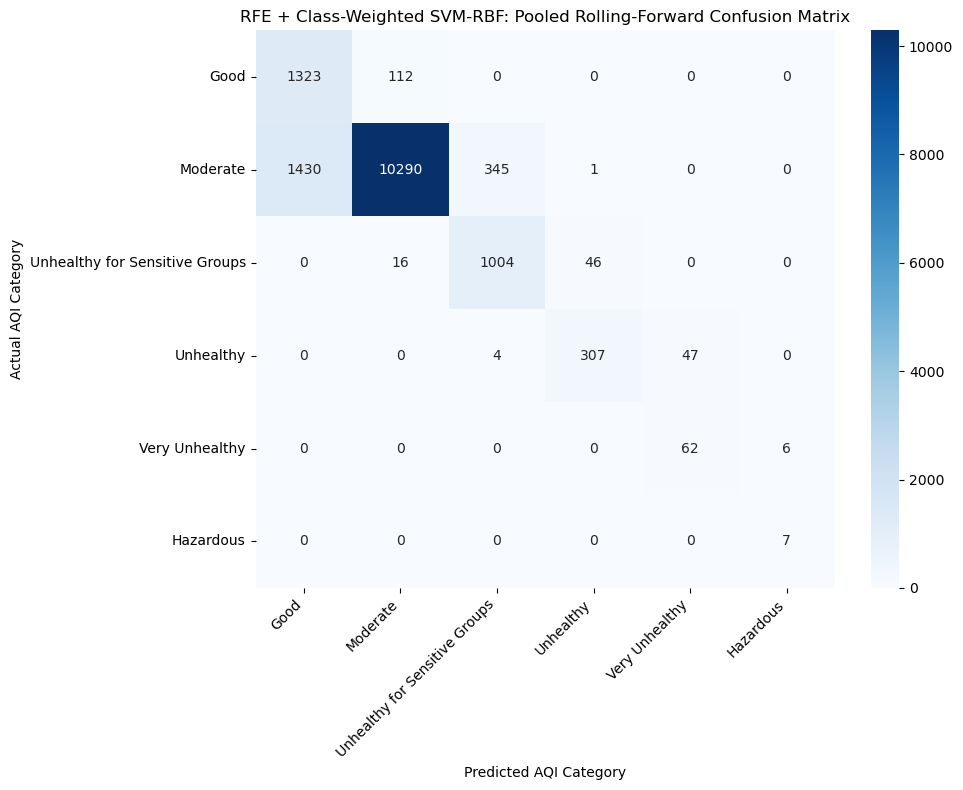

In [100]:
# ============================================================
# PLOT 1 — RAW COUNTS
# ============================================================

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_rfe_weighted_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=AQI_LABELS,
    yticklabels=AQI_LABELS
)

plt.xlabel("Predicted AQI Category")
plt.ylabel("Actual AQI Category")
plt.title(
    "RFE + Class-Weighted SVM-RBF: "
    "Pooled Rolling-Forward Confusion Matrix"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

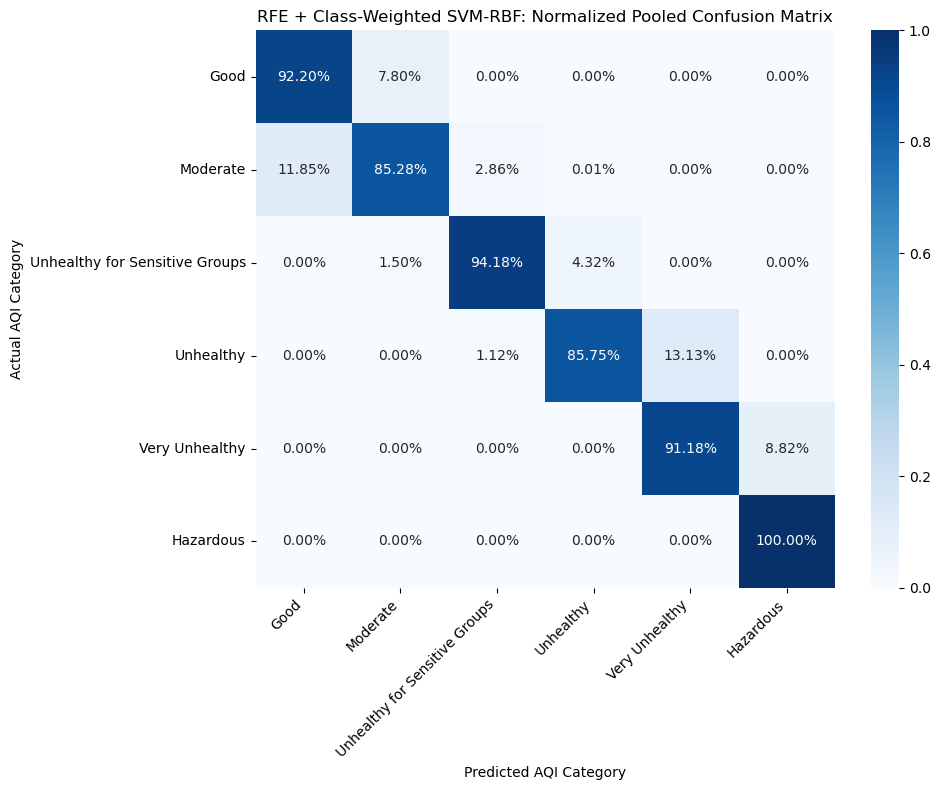

In [101]:
# ============================================================
# PLOT 2 — NORMALIZED BY ACTUAL CLASS
# ============================================================

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_rfe_weighted_norm_df,
    annot=True,
    fmt=".2%",
    cmap="Blues",
    xticklabels=AQI_LABELS,
    yticklabels=AQI_LABELS
)

plt.xlabel("Predicted AQI Category")
plt.ylabel("Actual AQI Category")
plt.title(
    "RFE + Class-Weighted SVM-RBF: "
    "Normalized Pooled Confusion Matrix"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [104]:
# ============================================================
# FINAL FOLD-TO-FOLD STABILITY ANALYSIS
# Uses the ACTUAL results already generated in the notebook
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. Convert any fold-result object to a DataFrame
# ------------------------------------------------------------

def ensure_fold_dataframe(results, name="results"):

    # Already a DataFrame
    if isinstance(results, pd.DataFrame):
        df = results.copy()

    # List of dictionaries
    elif isinstance(results, list):
        df = pd.DataFrame(results)

    # Dictionary
    elif isinstance(results, dict):
        df = pd.DataFrame(results)

    else:
        raise TypeError(
            f"{name} has unsupported type: {type(results)}"
        )

    return df


# ------------------------------------------------------------
# 2. Convert the four ACTUAL notebook result objects
# ------------------------------------------------------------

full_weighted_folds = ensure_fold_dataframe(
    baseline_fold_results_recovered,
    "Full + Class-Weighted SVM"
)

full_smote_folds = ensure_fold_dataframe(
    smote_fold_results,
    "Full + Controlled SMOTE"
)

rfe_weighted_folds = ensure_fold_dataframe(
    rfe_weighted_fold_results,
    "RFE + Class-Weighted SVM"
)

rfe_smote_folds = ensure_fold_dataframe(
    rfe_smote_fold_results,
    "RFE + Controlled SMOTE"
)


# ------------------------------------------------------------
# 3. Verify the structure before calculating anything
# ------------------------------------------------------------

print("Fold-result object types after conversion:")
print("------------------------------------------")

print(
    "Full + Class-Weighted SVM:",
    type(full_weighted_folds),
    full_weighted_folds.shape
)

print(
    "Full + Controlled SMOTE:",
    type(full_smote_folds),
    full_smote_folds.shape
)

print(
    "RFE + Class-Weighted SVM:",
    type(rfe_weighted_folds),
    rfe_weighted_folds.shape
)

print(
    "RFE + Controlled SMOTE:",
    type(rfe_smote_folds),
    rfe_smote_folds.shape
)


# ------------------------------------------------------------
# 4. Required metrics
# ------------------------------------------------------------

metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]


# ------------------------------------------------------------
# 5. Check that all required columns exist
# ------------------------------------------------------------

for name, df in {
    "Full + Class-Weighted SVM": full_weighted_folds,
    "Full + Controlled SMOTE": full_smote_folds,
    "RFE + Class-Weighted SVM": rfe_weighted_folds,
    "RFE + Controlled SMOTE": rfe_smote_folds
}.items():

    missing = [
        metric for metric in metrics
        if metric not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{name} is missing columns: {missing}\n"
            f"Available columns: {list(df.columns)}"
        )


# ------------------------------------------------------------
# 6. Calculate fold stability
# ------------------------------------------------------------

def calculate_fold_stability(df, model_name):

    rows = []

    for metric in metrics:

        values = pd.to_numeric(
            df[metric],
            errors="coerce"
        )

        rows.append({
            "Model": model_name,
            "Metric": metric,
            "Mean (%)": values.mean() * 100,
            "Std (%)": values.std(ddof=1) * 100,
            "Minimum (%)": values.min() * 100,
            "Maximum (%)": values.max() * 100
        })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 7. Combine all four models
# ------------------------------------------------------------

fold_stability = pd.concat([

    calculate_fold_stability(
        full_weighted_folds,
        "Full + Class-Weighted SVM"
    ),

    calculate_fold_stability(
        full_smote_folds,
        "Full + Controlled SMOTE"
    ),

    calculate_fold_stability(
        rfe_weighted_folds,
        "RFE + Class-Weighted SVM"
    ),

    calculate_fold_stability(
        rfe_smote_folds,
        "RFE + Controlled SMOTE"
    )

], ignore_index=True)


# ------------------------------------------------------------
# 8. Round for presentation
# ------------------------------------------------------------

fold_stability = fold_stability.round(2)

display(fold_stability)

Fold-result object types after conversion:
------------------------------------------
Full + Class-Weighted SVM: <class 'pandas.core.frame.DataFrame'> (15, 6)
Full + Controlled SMOTE: <class 'pandas.core.frame.DataFrame'> (15, 9)
RFE + Class-Weighted SVM: <class 'pandas.core.frame.DataFrame'> (15, 9)
RFE + Controlled SMOTE: <class 'pandas.core.frame.DataFrame'> (15, 9)


,Model,Metric,Mean (%),Std (%),Minimum (%),Maximum (%)
0,Full + Class-Weighted SVM,Accuracy,82.54,15.50,37.60,98.30
1,Full + Class-Weighted SVM,Macro Precision,71.48,11.71,49.71,88.18
2,Full + Class-Weighted SVM,Macro Recall,78.19,17.99,35.41,99.41
3,Full + Class-Weighted SVM,Macro F1,69.52,17.78,29.66,87.82
4,Full + Class-Weighted SVM,Weighted F1,84.06,12.63,52.35,98.48
5,Full + Controlled SMOTE,Accuracy,89.28,10.91,55.70,99.60
6,Full + Controlled SMOTE,Macro Precision,72.23,24.25,26.97,99.86
7,Full + Controlled SMOTE,Macro Recall,69.38,19.66,33.33,96.19
8,Full + Controlled SMOTE,Macro F1,68.52,20.92,29.81,96.60
9,Full + Controlled SMOTE,Weighted F1,87.60,14.89,39.85,99.58


In [105]:
# ============================================================
# THESIS-READY FOLD STABILITY TABLE
# ============================================================

stability_thesis = fold_stability.pivot(
    index="Model",
    columns="Metric",
    values=["Mean (%)", "Std (%)"]
)

display(
    stability_thesis.round(2)
)

Mean (%)                                        \
Metric                    Accuracy Macro F1 Macro Precision Macro Recall   
Model                                                                      
Full + Class-Weighted SVM    82.54    69.52           71.48        78.19   
Full + Controlled SMOTE      89.28    68.52           72.23        69.38   
RFE + Class-Weighted SVM     86.62    75.95           73.53        89.14   
RFE + Controlled SMOTE       92.10    76.66           85.98        75.52   

                                       Std (%)                           \
Metric                    Weighted F1 Accuracy Macro F1 Macro Precision   
Model                                                                     
Full + Class-Weighted SVM       84.06    15.50    17.78           11.71   
Full + Controlled SMOTE         87.60    10.91    20.92           24.25   
RFE + Class-Weighted SVM        88.06     6.95     9.74            8.75   
RFE + Controlled SMOTE          90.14    10.26    18.38           16.52   

                                                    
Metric                    Macro Recall Weighted F1  
Model                                               
Full + Class-Weighted SVM        17.99       12.63  
Full + Controlled SMOTE          19.66       14.89  
RFE + Class-Weighted SVM          9.38        6.46  
RFE + Controlled SMOTE           17.24       13.59

C:\Users\HP\AppData\Local\Temp\ipykernel_3732\1464177475.py:92: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\HP\AppData\Local\Temp\ipykernel_3732\1464177475.py:92: UserWarning: Glyph 8325 (\N{SUBSCRIPT FIVE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\HP\AppData\Local\Temp\ipykernel_3732\1464177475.py:94: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(
C:\Users\HP\AppData\Local\Temp\ipykernel_3732\1464177475.py:94: UserWarning: Glyph 8325 (\N{SUBSCRIPT FIVE}) missing from font(s) Arial.
  plt.savefig(
c:\Users\HP\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\HP\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8325 (\N{SUBSCRIPT FIVE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


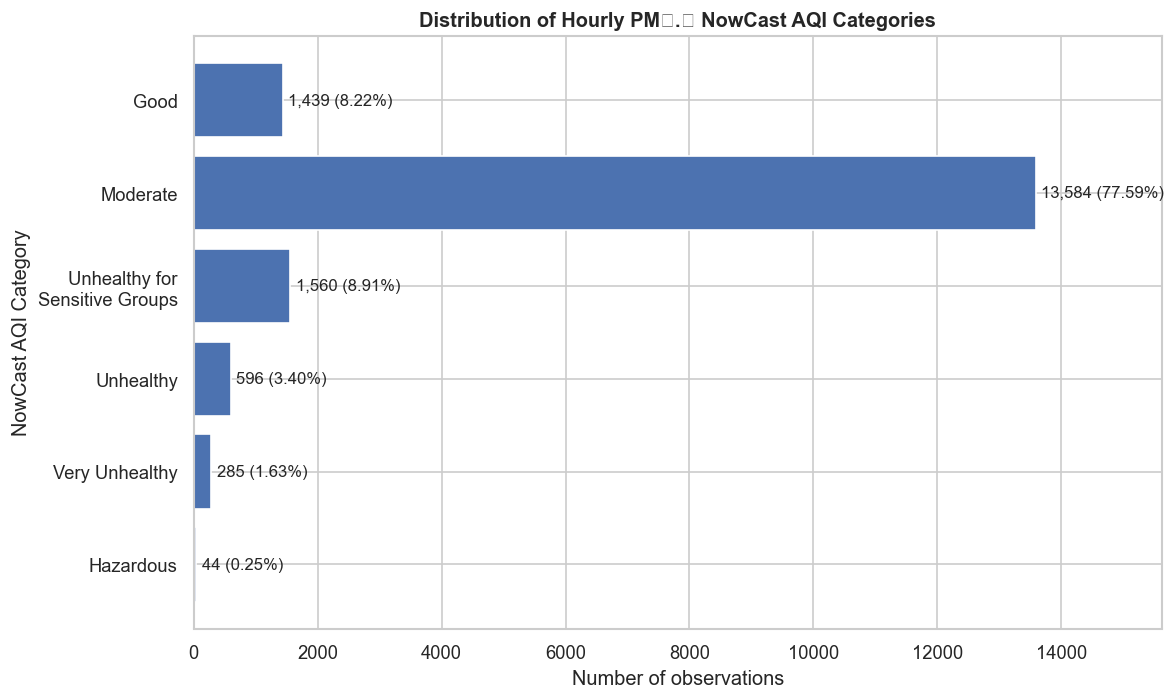

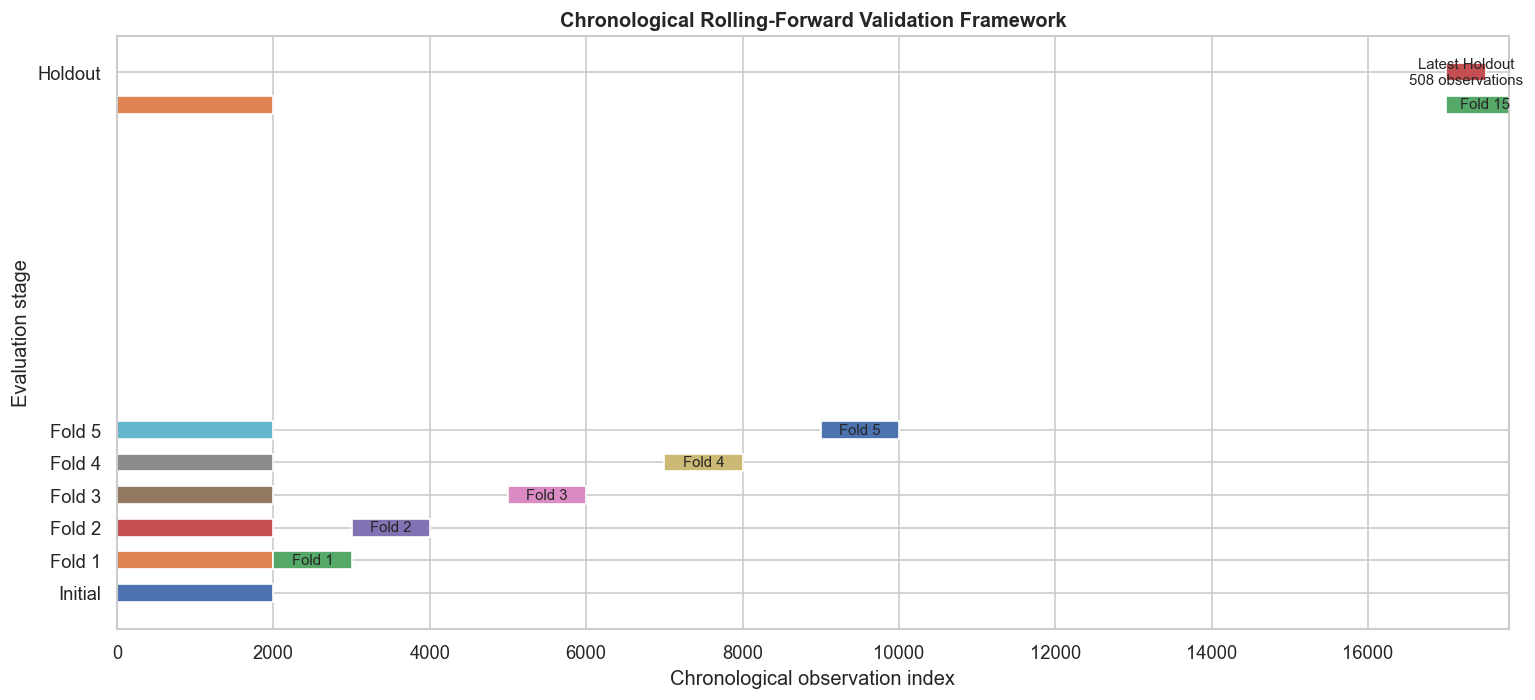

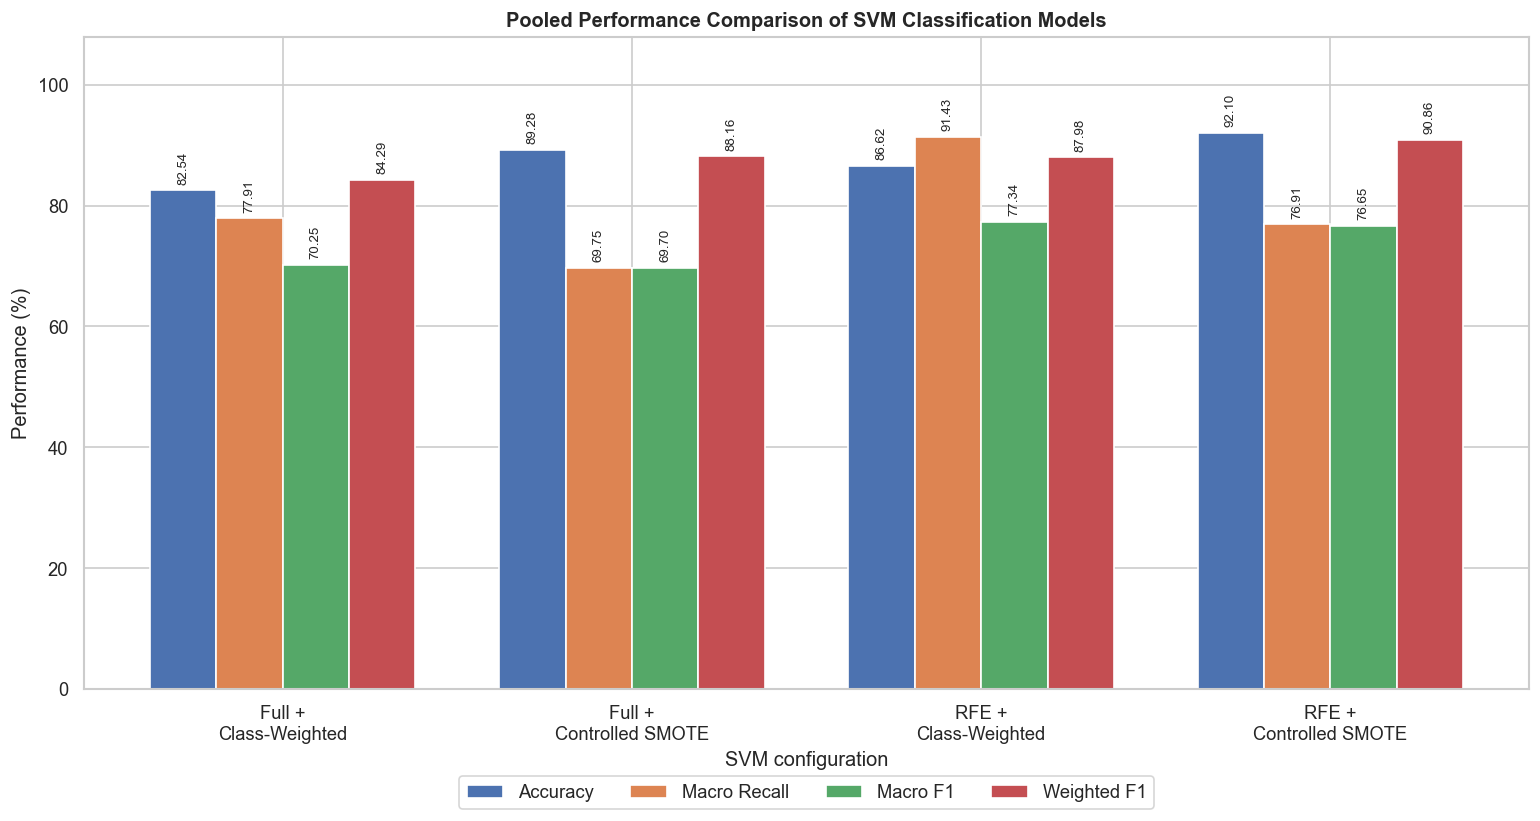

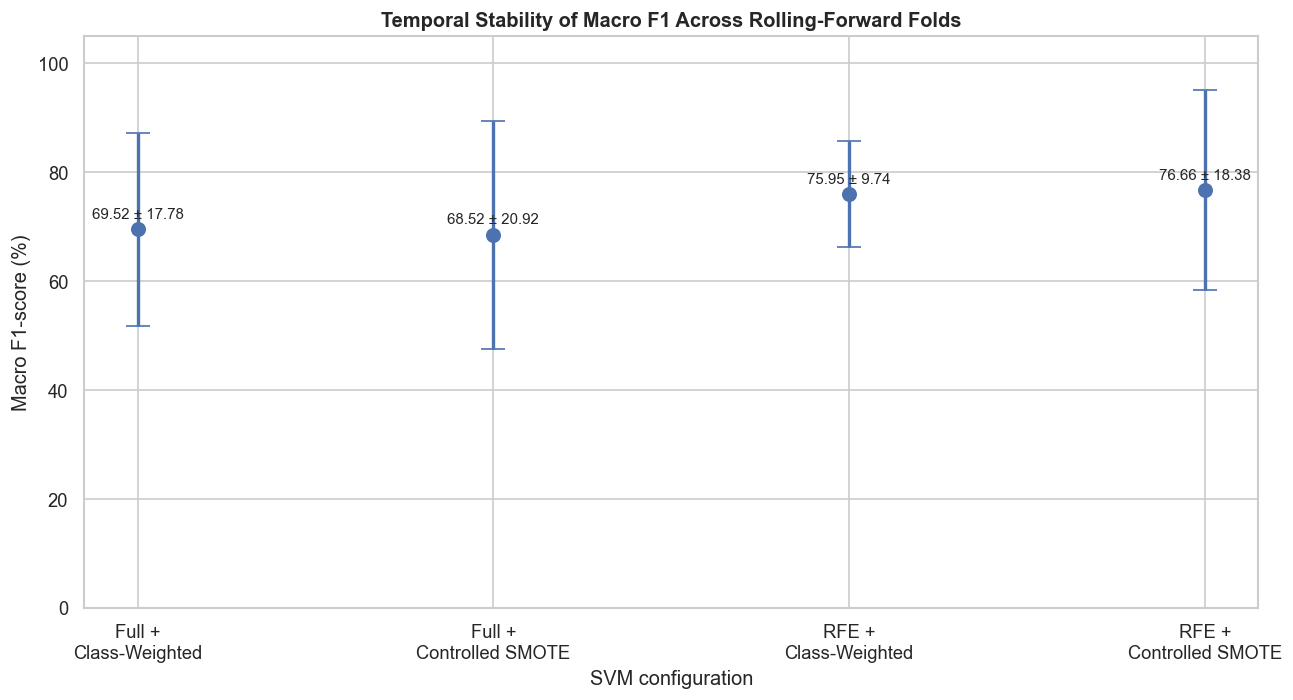

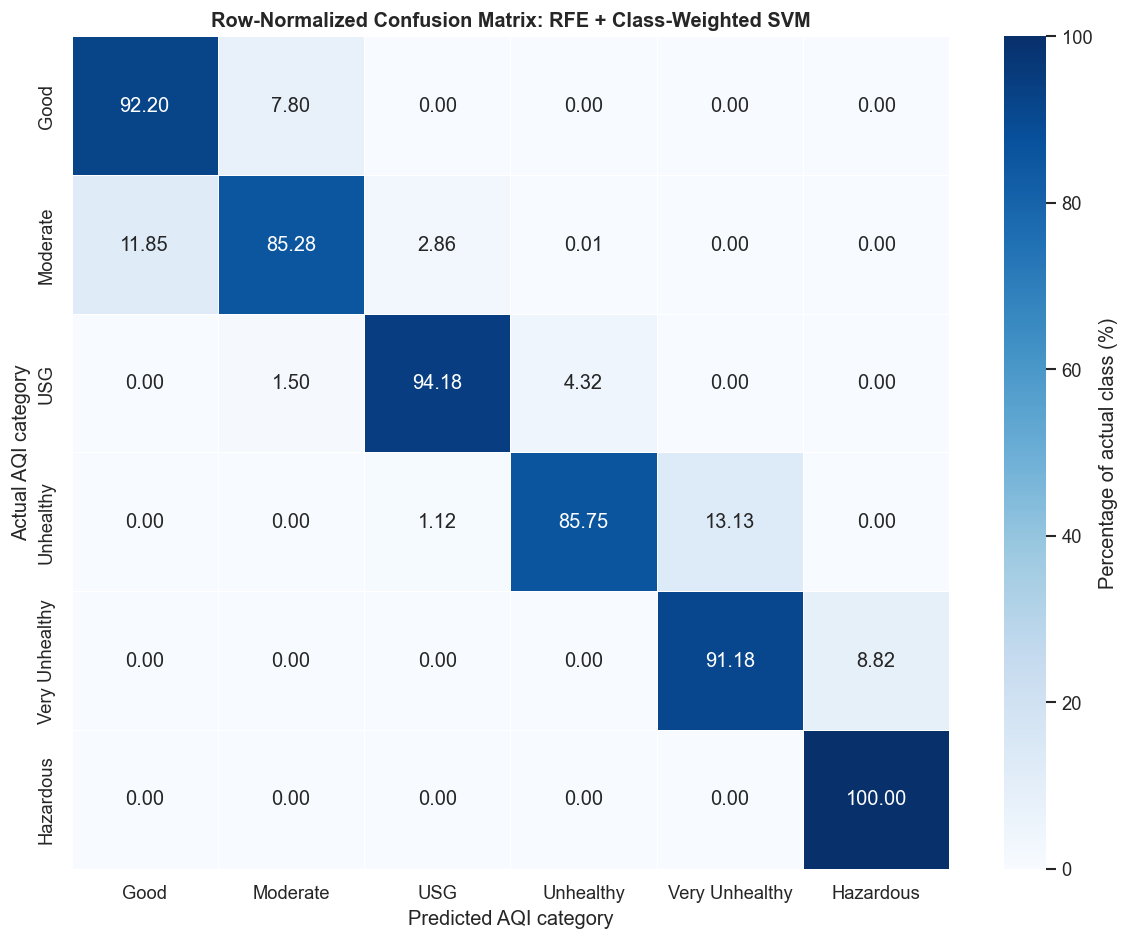

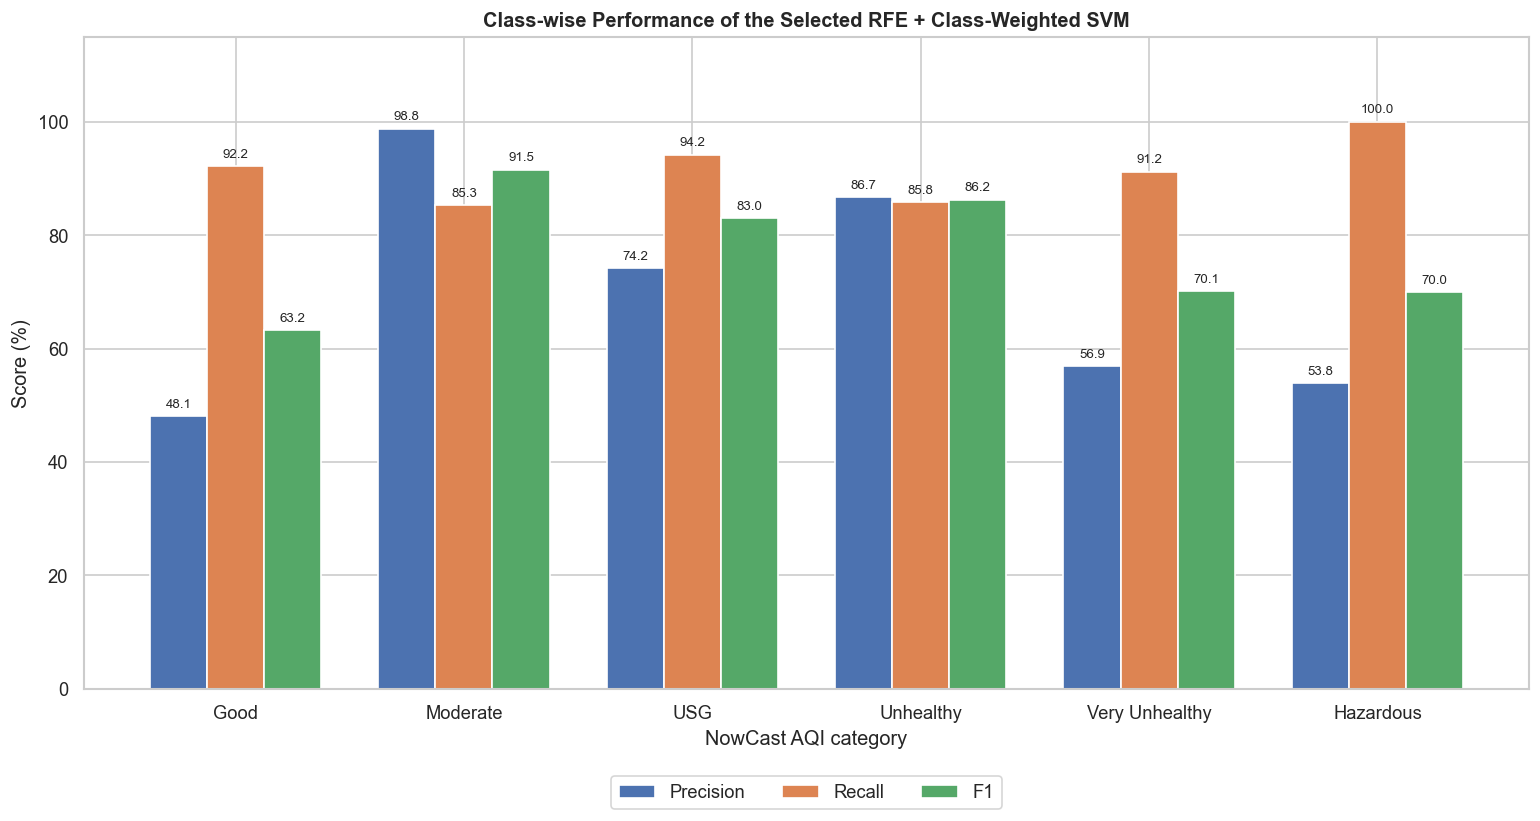

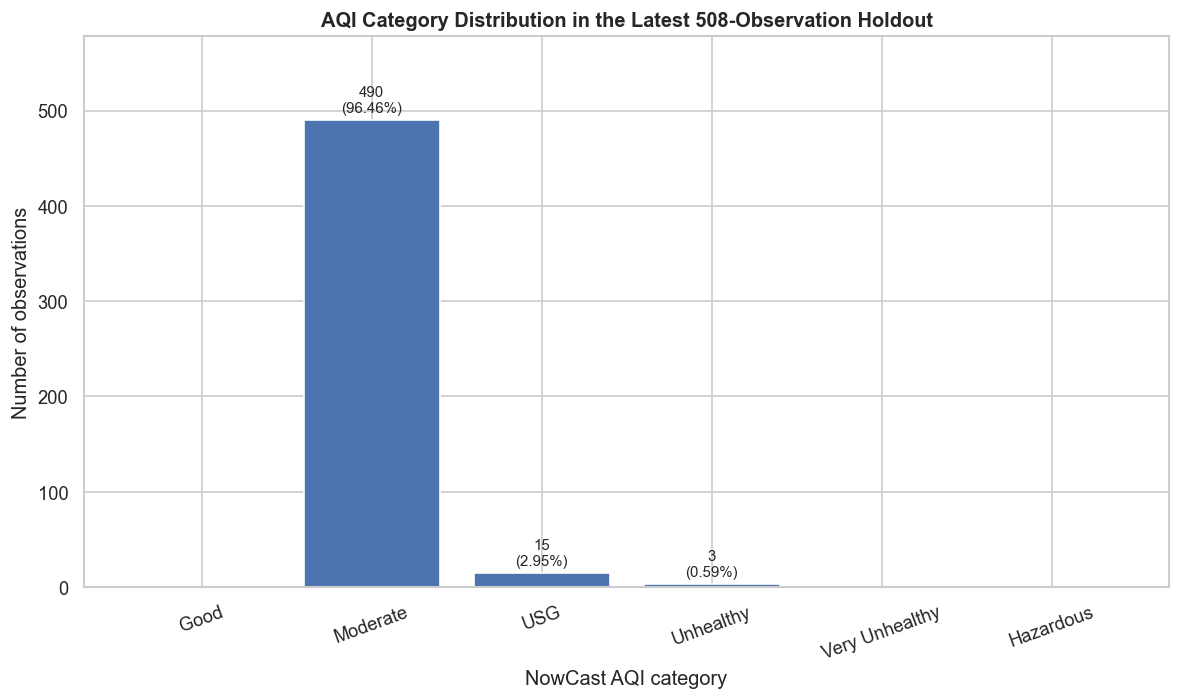


CHAPTER FOUR VISUALS GENERATED
✓ chapter4_figures\Figure_4_1_AQI_Category_Distribution.png
✓ chapter4_figures\Figure_4_2_Rolling_Forward_Validation.png
✓ chapter4_figures\Figure_4_3_Pooled_SVM_Performance.png
✓ chapter4_figures\Figure_4_4_Macro_F1_Fold_Stability.png
✓ chapter4_figures\Figure_4_5_Selected_Model_Confusion_Matrix.png
✓ chapter4_figures\Figure_4_6_Selected_Model_Classwise_Performance.png
✓ chapter4_figures\Figure_4_7_Latest_Holdout_Distribution.png

All figures saved at 600 DPI.


In [1]:
# ============================================================
# CHAPTER FOUR — FINAL CLASSIFICATION VISUALS
# ============================================================
# Generates:
#   Figure 4.1 — NowCast AQI Category Distribution
#   Figure 4.2 — Rolling-Forward Validation Design
#   Figure 4.3 — Pooled SVM Performance Comparison
#   Figure 4.4 — Fold Stability (Mean ± SD Macro F1)
#   Figure 4.5 — Selected Model Confusion Matrix
#   Figure 4.6 — Selected Model Class-wise Performance
#   Figure 4.7 — Latest 508-Observation Holdout
#
# All numerical results are based on the actual executed
# classification results established in the notebook.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ------------------------------------------------------------
# 1. Output directory
# ------------------------------------------------------------

FIG_DIR = Path("chapter4_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Thesis-friendly plotting defaults
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 600,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 15
})

sns.set_theme(style="whitegrid")


# ============================================================
# FIGURE 4.1
# NowCast AQI Category Distribution
# ============================================================

aqi_categories = [
    "Good",
    "Moderate",
    "Unhealthy for\nSensitive Groups",
    "Unhealthy",
    "Very Unhealthy",
    "Hazardous"
]

aqi_counts = [1439, 13584, 1560, 596, 285, 44]
aqi_total = sum(aqi_counts)
aqi_percent = [x / aqi_total * 100 for x in aqi_counts]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    aqi_categories,
    aqi_counts
)

ax.invert_yaxis()

for bar, count, pct in zip(bars, aqi_counts, aqi_percent):
    ax.text(
        bar.get_width() + aqi_total * 0.005,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} ({pct:.2f}%)",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Distribution of Hourly PM₂.₅ NowCast AQI Categories",
    fontweight="bold"
)

ax.set_xlabel("Number of observations")
ax.set_ylabel("NowCast AQI Category")

ax.set_xlim(0, max(aqi_counts) * 1.15)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "Figure_4_1_AQI_Category_Distribution.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 4.2
# Rolling-Forward Validation Design
# ============================================================

fig, ax = plt.subplots(figsize=(13, 6))

# Initial training period
ax.barh(
    0,
    2000,
    left=0,
    height=0.55,
    label="Training"
)

# Show first five folds and last fold to keep diagram clean
folds_to_show = [
    (1, 0, 2000, 2000),
    (2, 2000, 3000, 2000),
    (3, 4000, 5000, 2000),
    (4, 6000, 7000, 2000),
    (5, 8000, 9000, 2000),
    (15, 16000, 17000, 2000)
]

# Training and test blocks
for fold, train_start, test_start, train_size in folds_to_show:

    # Training portion
    ax.barh(
        fold,
        train_size,
        left=0,
        height=0.55
    )

    # Test portion
    ax.barh(
        fold,
        1000,
        left=test_start,
        height=0.55
    )

    ax.text(
        test_start + 500,
        fold,
        f"Fold {fold}",
        ha="center",
        va="center",
        fontsize=9
    )

# Latest holdout
ax.barh(
    16,
    508,
    left=17000,
    height=0.55
)

ax.text(
    17000 + 254,
    16,
    "Latest Holdout\n508 observations",
    ha="center",
    va="center",
    fontsize=9
)

ax.set_yticks([0, 1, 2, 3, 4, 5, 16])
ax.set_yticklabels([
    "Initial",
    "Fold 1",
    "Fold 2",
    "Fold 3",
    "Fold 4",
    "Fold 5",
    "Holdout"
])

ax.set_xlabel("Chronological observation index")
ax.set_ylabel("Evaluation stage")

ax.set_title(
    "Chronological Rolling-Forward Validation Framework",
    fontweight="bold"
)

ax.set_xlim(0, 17800)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "Figure_4_2_Rolling_Forward_Validation.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 4.3
# Pooled SVM Performance Comparison
# ============================================================

models = [
    "Full +\nClass-Weighted",
    "Full +\nControlled SMOTE",
    "RFE +\nClass-Weighted",
    "RFE +\nControlled SMOTE"
]

pooled_results = pd.DataFrame({
    "Accuracy": [82.54, 89.28, 86.62, 92.10],
    "Macro Precision": [66.23, 72.76, 69.75, 82.07],
    "Macro Recall": [77.91, 69.75, 91.43, 76.91],
    "Macro F1": [70.25, 69.70, 77.34, 76.65],
    "Weighted F1": [84.29, 88.16, 87.98, 90.86]
}, index=models)

# We emphasize the most important balanced metrics.
metrics_to_plot = [
    "Accuracy",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]

x = np.arange(len(models))
width = 0.19

fig, ax = plt.subplots(figsize=(13, 7))

for i, metric in enumerate(metrics_to_plot):

    offset = (i - 1.5) * width

    bars = ax.bar(
        x + offset,
        pooled_results[metric],
        width,
        label=metric
    )

    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 1,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

ax.set_xticks(x)
ax.set_xticklabels(models)

ax.set_ylabel("Performance (%)")
ax.set_xlabel("SVM configuration")

ax.set_ylim(0, 108)

ax.set_title(
    "Pooled Performance Comparison of SVM Classification Models",
    fontweight="bold"
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=4,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "Figure_4_3_Pooled_SVM_Performance.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 4.4
# Fold Stability — Mean ± SD Macro F1
# ============================================================

stability = pd.DataFrame({
    "Model": models,
    "Mean Macro F1": [69.52, 68.52, 75.95, 76.66],
    "SD Macro F1": [17.78, 20.92, 9.74, 18.38]
})

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(stability))

ax.errorbar(
    x,
    stability["Mean Macro F1"],
    yerr=stability["SD Macro F1"],
    fmt="o",
    capsize=7,
    markersize=8,
    linewidth=2
)

for i, row in stability.iterrows():

    ax.text(
        i,
        row["Mean Macro F1"] + 1.5,
        f"{row['Mean Macro F1']:.2f} ± {row['SD Macro F1']:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(models)

ax.set_ylabel("Macro F1-score (%)")
ax.set_xlabel("SVM configuration")

ax.set_ylim(0, 105)

ax.set_title(
    "Temporal Stability of Macro F1 Across Rolling-Forward Folds",
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "Figure_4_4_Macro_F1_Fold_Stability.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 4.5
# Selected Model — Row-Normalized Confusion Matrix
# ============================================================

class_names = [
    "Good",
    "Moderate",
    "USG",
    "Unhealthy",
    "Very Unhealthy",
    "Hazardous"
]

# Actual pooled confusion matrix for:
# RFE + Class-Weighted SVM
cm = np.array([
    [1323, 112,   0,   0,  0, 0],
    [1430, 10290, 345, 1,  0, 0],
    [0,    16,   1004, 46, 0, 0],
    [0,     0,      4, 307, 47, 0],
    [0,     0,      0,   0, 62, 6],
    [0,     0,      0,   0,  0, 7]
])

# Row normalization = class-wise recall distribution
cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "Percentage of actual class (%)"},
    linewidths=0.5,
    ax=ax
)

ax.set_xlabel("Predicted AQI category")
ax.set_ylabel("Actual AQI category")

ax.set_title(
    "Row-Normalized Confusion Matrix: RFE + Class-Weighted SVM",
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "Figure_4_5_Selected_Model_Confusion_Matrix.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 4.6
# Selected Model — Class-wise Precision, Recall and F1
# ============================================================

classwise = pd.DataFrame({
    "Precision": [48.0567, 98.7714, 74.2055, 86.7232, 56.8807, 53.8462],
    "Recall": [92.1951, 85.2810, 94.1839, 85.7542, 91.1765, 100.0000],
    "F1": [63.1805, 91.5318, 83.0095, 86.2360, 70.0565, 70.0000]
}, index=class_names)

x = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(13, 7))

for i, metric in enumerate(["Precision", "Recall", "F1"]):

    bars = ax.bar(
        x + (i - 1) * width,
        classwise[metric],
        width,
        label=metric
    )

    for bar in bars:

        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 1,
            f"{height:.1f}",
            ha="center",
            va="bottom",
            fontsize=8
        )

ax.set_xticks(x)
ax.set_xticklabels(class_names)

ax.set_ylabel("Score (%)")
ax.set_xlabel("NowCast AQI category")

ax.set_ylim(0, 115)

ax.set_title(
    "Class-wise Performance of the Selected RFE + Class-Weighted SVM",
    fontweight="bold"
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "Figure_4_6_Selected_Model_Classwise_Performance.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 4.7
# Latest 508-Observation Holdout
# ============================================================

holdout_categories = [
    "Good",
    "Moderate",
    "USG",
    "Unhealthy",
    "Very Unhealthy",
    "Hazardous"
]

holdout_counts = [0, 490, 15, 3, 0, 0]

holdout_percent = [
    count / sum(holdout_counts) * 100
    for count in holdout_counts
]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    holdout_categories,
    holdout_counts
)

for bar, count, pct in zip(
    bars,
    holdout_counts,
    holdout_percent
):

    if count > 0:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            count + 5,
            f"{count}\n({pct:.2f}%)",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_ylabel("Number of observations")
ax.set_xlabel("NowCast AQI category")

ax.set_title(
    "AQI Category Distribution in the Latest 508-Observation Holdout",
    fontweight="bold"
)

ax.set_ylim(0, max(holdout_counts) * 1.18)

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "Figure_4_7_Latest_Holdout_Distribution.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FINAL CHECK
# ============================================================

print("\n" + "=" * 65)
print("CHAPTER FOUR VISUALS GENERATED")
print("=" * 65)

for file in sorted(FIG_DIR.glob("*.png")):
    print(f"✓ {file}")

print("\nAll figures saved at 600 DPI.")